In [1]:
import os
NOTEBOOK_NAME = 'Training75ClassOutputs'
BASE_DIR = f'/mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/{NOTEBOOK_NAME}'
os.makedirs(BASE_DIR, exist_ok=True)
os.chdir(BASE_DIR)
print('Working directory sekarang:', os.getcwd())

Working directory sekarang: /mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/Training75ClassOutputs


In [2]:
%pip install -q numpy==1.26.4 tensorflow==2.17.0 matplotlib==3.9.4 scikit-learn==1.5.2 protobuf==4.25.3

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from keras.utils import to_categorical
from keras.models import Model
from keras.layers import (
    Input, Dense, Dropout, BatchNormalization,
    Bidirectional, LSTM, Layer, GaussianNoise
)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.regularizers import l2

# ====== KONFIGURASI EKSPERIMEN — UBAH DI SINI SAJA ======
import datetime

N_EPOCHS = 500
RUN_TIMESTAMP = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
PATH_CONFIGURATION_GENERAL = f'Epoch{N_EPOCHS}_{RUN_TIMESTAMP}'
os.makedirs(PATH_CONFIGURATION_GENERAL, exist_ok=True)
print(f'Output eksperimen ini akan disimpan ke folder: {PATH_CONFIGURATION_GENERAL}')
# ==========================================================

print(f'TensorFlow  : {tf.__version__}')
print(f'Keras       : {tf.keras.__version__}')
print(f'GPU tersedia: {tf.config.list_physical_devices("GPU")}')

2026-09-16 09:35:47.672623: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-16 09:35:47.708279: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-09-16 09:35:47.725200: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-09-16 09:35:47.729639: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-16 09:35:47.757605: I tensorflow/core/platform/cpu_feature_guar

Output eksperimen ini akan disimpan ke folder: Epoch500_20260916_093550
TensorFlow  : 2.17.0
Keras       : 3.12.4
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1789526150.536577   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1789526150.787515   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1789526150.787566   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [4]:
DATA_PATH = '/mnt/d/Projects/SIBI Recognition Lecturers/Dataset Keypoints'
sequence_length = 30
FITUR_PER_FRAME = 258
MODEL_OUTPUT    = f'{PATH_CONFIGURATION_GENERAL}/model25class.keras'
MODEL_OUTPUT_H5  = f'{PATH_CONFIGURATION_GENERAL}/model25class.h5'
TEMP_CHECKPOINT = f'{PATH_CONFIGURATION_GENERAL}/temp_checkpoint.keras'

actions = np.array([
    'Adik', 'Agustus', 'Apa', 'April', 'Ayah', 'Baik', 'Berapa', 'Bertemu',
    'Cantik', 'Dari', 'Desember', 'Dia', 'Dimana', 'Februari', 'Ganteng',
    'Gemuk', 'Hallo', 'Hobi', 'Ibu', 'Januari', 'Juli', 'Jumat', 'Juni',
    'Jurusan', 'Kabar', 'Kakek', 'Kalian', 'Kami', 'Kamis', 'Kampus',
    'Kamu', 'Kelas', 'Keluarga', 'Kemana', 'Kenapa', 'Kita', 'Kuliah',
    'Kurus', 'Lucu', 'Malam', 'Maret', 'Mau', 'Mei', 'Mereka', 'Minggu',
    'Nama', 'November', 'Oktober', 'Pagi', 'Pelit', 'Pendidikan', 'Pintar',
    'Pulang', 'Rabu', 'Ramah', 'Rendah Hati', 'Sabar', 'Sabtu', 'Sakit',
    'Sampai Jumpa', 'Saya', 'Sekolah', 'Selamat', 'Selasa', 'Semester',
    'Senang', 'Senin', 'September', 'Siang', 'Siapa', 'Sore', 'Suka',
    'Terimakasih', 'Tinggal', 'Umur'
])

POSE_DIM   = 132
LH_DIM     = 63
RH_DIM     = 63
POSE_END   = POSE_DIM
LH_END     = POSE_END + LH_DIM
RH_END     = LH_END + RH_DIM

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


print('Kelas yang dilatih :', actions)
print('Jumlah kelas        :', len(actions))
print('Sequence length     :', sequence_length)
print('Fitur per frame     :', FITUR_PER_FRAME)
print('  - Pose : 0..{}    (132 = 33 x 4)'.format(POSE_END - 1))
print('  - LH   : {}..{}  (63 = 21 x 3)'.format(POSE_END, LH_END - 1))
print('  - RH   : {}..{}  (63 = 21 x 3)'.format(LH_END, RH_END - 1))
print('Output model        :', MODEL_OUTPUT)

os.makedirs(os.path.dirname(MODEL_OUTPUT), exist_ok=True)
os.makedirs(os.path.dirname(TEMP_CHECKPOINT), exist_ok=True)
print('✅ Folder output siap:', os.path.dirname(MODEL_OUTPUT))

Kelas yang dilatih : ['Adik' 'Agustus' 'Apa' 'April' 'Ayah' 'Baik' 'Berapa' 'Bertemu' 'Cantik'
 'Dari' 'Desember' 'Dia' 'Dimana' 'Februari' 'Ganteng' 'Gemuk' 'Hallo'
 'Hobi' 'Ibu' 'Januari' 'Juli' 'Jumat' 'Juni' 'Jurusan' 'Kabar' 'Kakek'
 'Kalian' 'Kami' 'Kamis' 'Kampus' 'Kamu' 'Kelas' 'Keluarga' 'Kemana'
 'Kenapa' 'Kita' 'Kuliah' 'Kurus' 'Lucu' 'Malam' 'Maret' 'Mau' 'Mei'
 'Mereka' 'Minggu' 'Nama' 'November' 'Oktober' 'Pagi' 'Pelit' 'Pendidikan'
 'Pintar' 'Pulang' 'Rabu' 'Ramah' 'Rendah Hati' 'Sabar' 'Sabtu' 'Sakit'
 'Sampai Jumpa' 'Saya' 'Sekolah' 'Selamat' 'Selasa' 'Semester' 'Senang'
 'Senin' 'September' 'Siang' 'Siapa' 'Sore' 'Suka' 'Terimakasih' 'Tinggal'
 'Umur']
Jumlah kelas        : 75
Sequence length     : 30
Fitur per frame     : 258
  - Pose : 0..131    (132 = 33 x 4)
  - LH   : 132..194  (63 = 21 x 3)
  - RH   : 195..257  (63 = 21 x 3)
Output model        : Epoch500_20260916_093550/model25class.keras
✅ Folder output siap: Epoch500_20260916_093550


In [5]:
label_map = {label: num for num, label in enumerate(actions)}
print('Label map:', label_map)

sequences, labels = [], []

for action in actions:
    action_path = os.path.join(DATA_PATH, action)

    if not os.path.exists(action_path):
        print(f'⚠️  Folder tidak ditemukan: {action_path}')
        continue

    sequence_folders = sorted(
        [f for f in os.listdir(action_path) if f.isdigit()],
        key=int
    )

    loaded, skipped = 0, 0
    for sequence in sequence_folders:
        window = []
        try:
            for frame_num in range(sequence_length):
                res = np.load(os.path.join(action_path, sequence, f'{frame_num}.npy'))
                if res.shape[0] != FITUR_PER_FRAME:
                    raise ValueError(f'Fitur {res.shape[0]} != {FITUR_PER_FRAME} — cek extract_keypoints!')
                window.append(res)
            sequences.append(np.array(window))
            labels.append(label_map[action])
            loaded += 1
        except Exception:
            skipped += 1

    print(f'  {action:12s}: {loaded} dimuat, {skipped} dilewati')

X     = np.array(sequences, dtype=np.float32)
y_int = np.array(labels)
y     = to_categorical(y_int, num_classes=len(actions))

print(f'\n✅ Shape X : {X.shape}')
print(f'✅ Shape y : {y.shape}')
print('\nDistribusi kelas:')
for u, c in zip(*np.unique(y_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c} sequence')

Label map: {'Adik': 0, 'Agustus': 1, 'Apa': 2, 'April': 3, 'Ayah': 4, 'Baik': 5, 'Berapa': 6, 'Bertemu': 7, 'Cantik': 8, 'Dari': 9, 'Desember': 10, 'Dia': 11, 'Dimana': 12, 'Februari': 13, 'Ganteng': 14, 'Gemuk': 15, 'Hallo': 16, 'Hobi': 17, 'Ibu': 18, 'Januari': 19, 'Juli': 20, 'Jumat': 21, 'Juni': 22, 'Jurusan': 23, 'Kabar': 24, 'Kakek': 25, 'Kalian': 26, 'Kami': 27, 'Kamis': 28, 'Kampus': 29, 'Kamu': 30, 'Kelas': 31, 'Keluarga': 32, 'Kemana': 33, 'Kenapa': 34, 'Kita': 35, 'Kuliah': 36, 'Kurus': 37, 'Lucu': 38, 'Malam': 39, 'Maret': 40, 'Mau': 41, 'Mei': 42, 'Mereka': 43, 'Minggu': 44, 'Nama': 45, 'November': 46, 'Oktober': 47, 'Pagi': 48, 'Pelit': 49, 'Pendidikan': 50, 'Pintar': 51, 'Pulang': 52, 'Rabu': 53, 'Ramah': 54, 'Rendah Hati': 55, 'Sabar': 56, 'Sabtu': 57, 'Sakit': 58, 'Sampai Jumpa': 59, 'Saya': 60, 'Sekolah': 61, 'Selamat': 62, 'Selasa': 63, 'Semester': 64, 'Senang': 65, 'Senin': 66, 'September': 67, 'Siang': 68, 'Siapa': 69, 'Sore': 70, 'Suka': 71, 'Terimakasih': 72, 'Ti

In [6]:
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X, y_int, test_size=0.30, random_state=SEED, stratify=y_int
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED, stratify=y_temp_raw
)

print(f'Train (asli) : {X_train_raw.shape[0]} sequence')
print(f'Val   (asli) : {X_val_raw.shape[0]} sequence')
print(f'Test  (asli) : {X_test_raw.shape[0]} sequence')
print('\nDistribusi train asli:')
for u, c in zip(*np.unique(y_train_raw, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')

Train (asli) : 2683 sequence
Val   (asli) : 575 sequence
Test  (asli) : 576 sequence

Distribusi train asli:
  Adik        : 35
  Agustus     : 36
  Apa         : 34
  April       : 36
  Ayah        : 35
  Baik        : 35
  Berapa      : 35
  Bertemu     : 36
  Cantik      : 34
  Dari        : 35
  Desember    : 35
  Dia         : 36
  Dimana      : 35
  Februari    : 35
  Ganteng     : 35
  Gemuk       : 34
  Hallo       : 36
  Hobi        : 35
  Ibu         : 36
  Januari     : 36
  Juli        : 40
  Jumat       : 36
  Juni        : 37
  Jurusan     : 37
  Kabar       : 36
  Kakek       : 34
  Kalian      : 36
  Kami        : 36
  Kamis       : 34
  Kampus      : 36
  Kamu        : 35
  Kelas       : 36
  Keluarga    : 34
  Kemana      : 34
  Kenapa      : 39
  Kita        : 36
  Kuliah      : 35
  Kurus       : 35
  Lucu        : 34
  Malam       : 35
  Maret       : 35
  Mau         : 38
  Mei         : 35
  Mereka      : 36
  Minggu      : 35
  Nama        : 35
  November    : 3

In [7]:
def split_features(seq):
    """Pisah seq (T, 258) → pose (T, 33, 4), lh (T, 21, 3), rh (T, 21, 3)."""
    pose = seq[:, :POSE_END].reshape(-1, 33, 4)
    lh   = seq[:, POSE_END:LH_END].reshape(-1, 21, 3)
    rh   = seq[:, LH_END:RH_END].reshape(-1, 21, 3)
    return pose, lh, rh


def merge_features(pose, lh, rh):
    """Gabungkan kembali ke seq (T, 258)."""
    T = pose.shape[0]
    return np.concatenate([
        pose.reshape(T, -1), lh.reshape(T, -1), rh.reshape(T, -1)
    ], axis=1).astype(np.float32)


def aug_gaussian_noise(seq, sigma=0.008):
    """Noise hanya pada x,y,z — visibility (kolom 4 pose) TIDAK di-noise."""
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3] + np.random.normal(0, sigma, pose[:, :, :3].shape)
    pose_vis = pose[:, :, 3:4]
    pose_new = np.concatenate([pose_xyz, pose_vis], axis=-1)
    lh_new = lh + np.random.normal(0, sigma, lh.shape)
    rh_new = rh + np.random.normal(0, sigma, rh.shape)
    return merge_features(pose_new, lh_new, rh_new)


def aug_scale(seq, scale_range=(0.93, 1.07)):
    """Scaling x,y,z saja — visibility TIDAK di-scale."""
    s = np.random.uniform(*scale_range)
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3] * s
    pose_vis = pose[:, :, 3:4]
    pose_new = np.concatenate([pose_xyz, pose_vis], axis=-1)
    return merge_features(pose_new, lh * s, rh * s)


def aug_time_warp(seq, factor_range=(0.85, 1.15)):
    """Time warping yang BENAR (versi sebelumnya buggy indexing)."""
    factor = np.random.uniform(*factor_range)
    T = seq.shape[0]
    new_T = max(2, int(T * factor))
    old_x = np.linspace(0, 1, T)
    new_x = np.linspace(0, 1, new_T)
    intermediate = np.array([
        np.interp(new_x, old_x, seq[:, fi]) for fi in range(seq.shape[1])
    ]).T
    final = np.array([
        np.interp(old_x, new_x, intermediate[:, fi]) for fi in range(seq.shape[1])
    ]).T
    return final.astype(np.float32)


def aug_frame_mask(seq, n_mask_range=(2, 6)):
    """Mask beberapa frame jadi 0 (simulasi occlusion)."""
    masked = seq.copy()
    n_mask = np.random.randint(*n_mask_range)
    mask_idx = np.random.choice(seq.shape[0], n_mask, replace=False)
    masked[mask_idx] = 0.0
    return masked


def aug_mirror_hands(seq):
    """
    Mirror horizontal: x → -x, dan SWAP tangan kiri ↔ kanan.
    PENTING untuk SIBI karena gerakan bisa pakai tangan kiri ATAU kanan.
    Kunci untuk membedakan Saya/Obat/Sabar yang trajectory-nya mirip.
    """
    pose, lh, rh = split_features(seq)

    pose_flipped = pose.copy()
    pose_flipped[:, :, 0] = -pose_flipped[:, :, 0]

    lh_flipped = lh.copy(); lh_flipped[:, :, 0] = -lh_flipped[:, :, 0]
    rh_flipped = rh.copy(); rh_flipped[:, :, 0] = -rh_flipped[:, :, 0]

    return merge_features(pose_flipped, rh_flipped, lh_flipped)


def aug_translation(seq, shift_range=0.03):
    """Geser kecil di x,y (simulasi posisi badan signer berbeda)."""
    dx = np.random.uniform(-shift_range, shift_range)
    dy = np.random.uniform(-shift_range, shift_range)
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] += dx; pose_xyz[:, :, 1] += dy
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)
    lh_new = lh.copy(); lh_new[:, :, 0] += dx; lh_new[:, :, 1] += dy
    rh_new = rh.copy(); rh_new[:, :, 0] += dx; rh_new[:, :, 1] += dy
    return merge_features(pose_new, lh_new, rh_new)


def augment_sequence(seq, label_idx):
    augs = [
        aug_gaussian_noise(seq),
        aug_scale(seq),
        aug_time_warp(seq),
        aug_frame_mask(seq),
        aug_mirror_hands(seq),
        aug_translation(seq),
    ]


    return augs


print('Melakukan augmentasi (HANYA pada train set)...')
X_train_aug_list = list(X_train_raw)
y_train_aug_list = list(y_train_raw)

for seq, lbl in zip(X_train_raw, y_train_raw):
    for aug_seq in augment_sequence(seq, lbl):
        X_train_aug_list.append(aug_seq)
        y_train_aug_list.append(lbl)

X_train = np.array(X_train_aug_list, dtype=np.float32)
y_train_int = np.array(y_train_aug_list)
y_train = to_categorical(y_train_int, num_classes=len(actions))

# Val & test TIDAK diaugmentasi (hanya konversi ke categorical)
X_val  = X_val_raw.astype(np.float32)
y_val  = to_categorical(y_val_raw, num_classes=len(actions))
X_test = X_test_raw.astype(np.float32)
y_test = to_categorical(y_test_raw, num_classes=len(actions))

print(f'\n✅ Train (setelah augmentasi) : {X_train.shape[0]}')
print(f'✅ Val                          : {X_val.shape[0]} (TIDAK diaugmentasi)')
print(f'✅ Test                         : {X_test.shape[0]} (TIDAK diaugmentasi)')

print('\nDistribusi kelas TRAIN setelah augmentasi:')
for u, c in zip(*np.unique(y_train_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')

Melakukan augmentasi (HANYA pada train set)...

✅ Train (setelah augmentasi) : 18781
✅ Val                          : 575 (TIDAK diaugmentasi)
✅ Test                         : 576 (TIDAK diaugmentasi)

Distribusi kelas TRAIN setelah augmentasi:
  Adik        : 245
  Agustus     : 252
  Apa         : 238
  April       : 252
  Ayah        : 245
  Baik        : 245
  Berapa      : 245
  Bertemu     : 252
  Cantik      : 238
  Dari        : 245
  Desember    : 245
  Dia         : 252
  Dimana      : 245
  Februari    : 245
  Ganteng     : 245
  Gemuk       : 238
  Hallo       : 252
  Hobi        : 245
  Ibu         : 252
  Januari     : 252
  Juli        : 280
  Jumat       : 252
  Juni        : 259
  Jurusan     : 259
  Kabar       : 252
  Kakek       : 238
  Kalian      : 252
  Kami        : 252
  Kamis       : 238
  Kampus      : 252
  Kamu        : 245
  Kelas       : 252
  Keluarga    : 238
  Kemana      : 238
  Kenapa      : 273
  Kita        : 252
  Kuliah      : 245
  Kurus       :

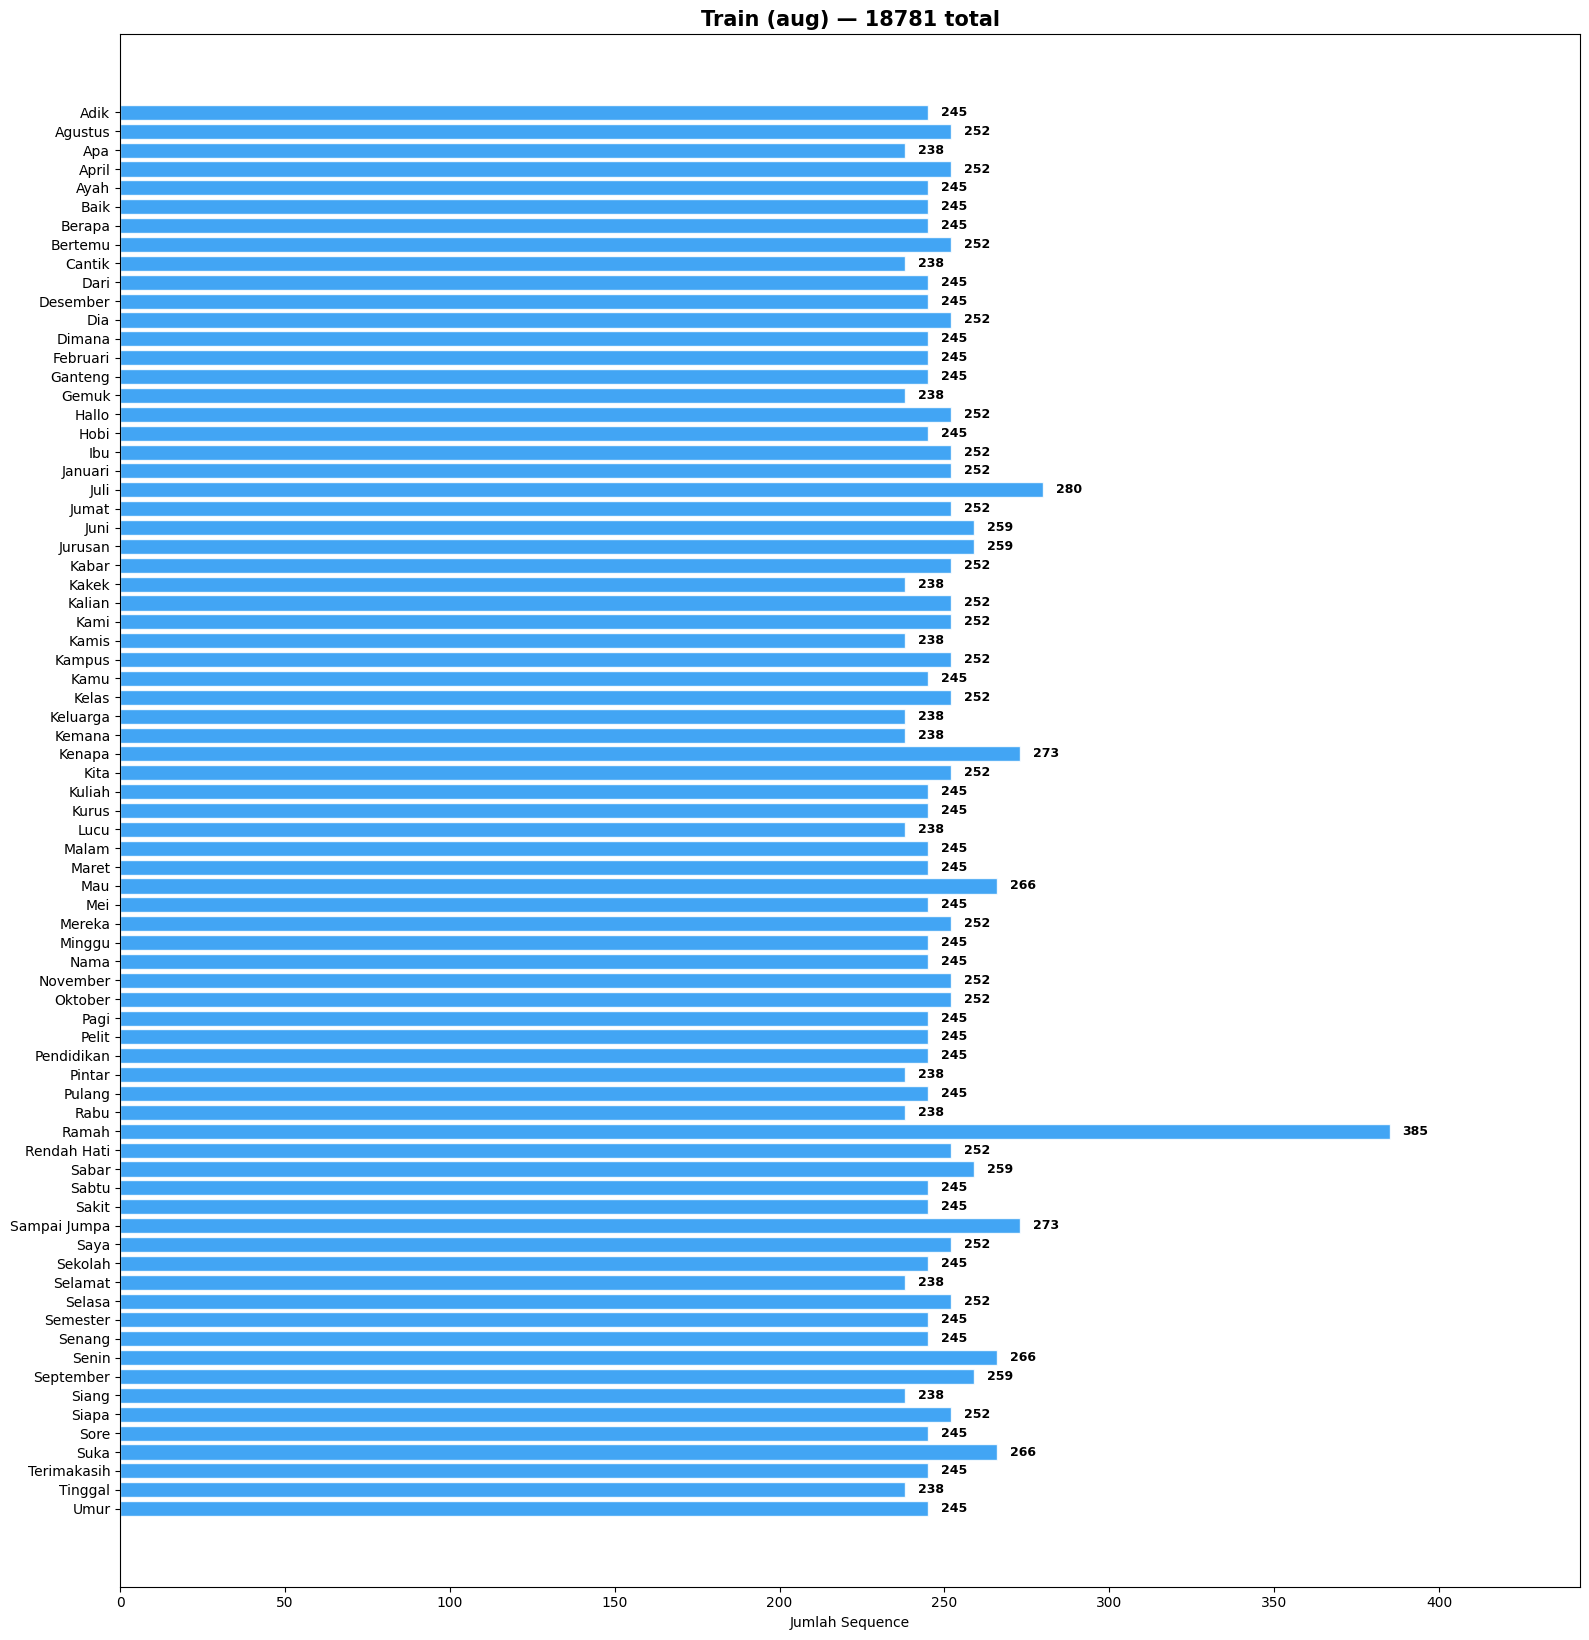

In [8]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

counts = np.sum(y_train, axis=0).astype(int)
bars = ax.barh(actions, counts, color='#2196F3', alpha=0.85, edgecolor='white')
ax.set_title(f'Train (aug) — {y_train.shape[0]} total', fontweight='bold', fontsize=15)
ax.set_xlabel('Jumlah Sequence')
ax.set_xlim(0, max(counts) * 1.15)
ax.invert_yaxis()

for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2,
            str(c), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_train.png', dpi=200, bbox_inches='tight')
plt.show()

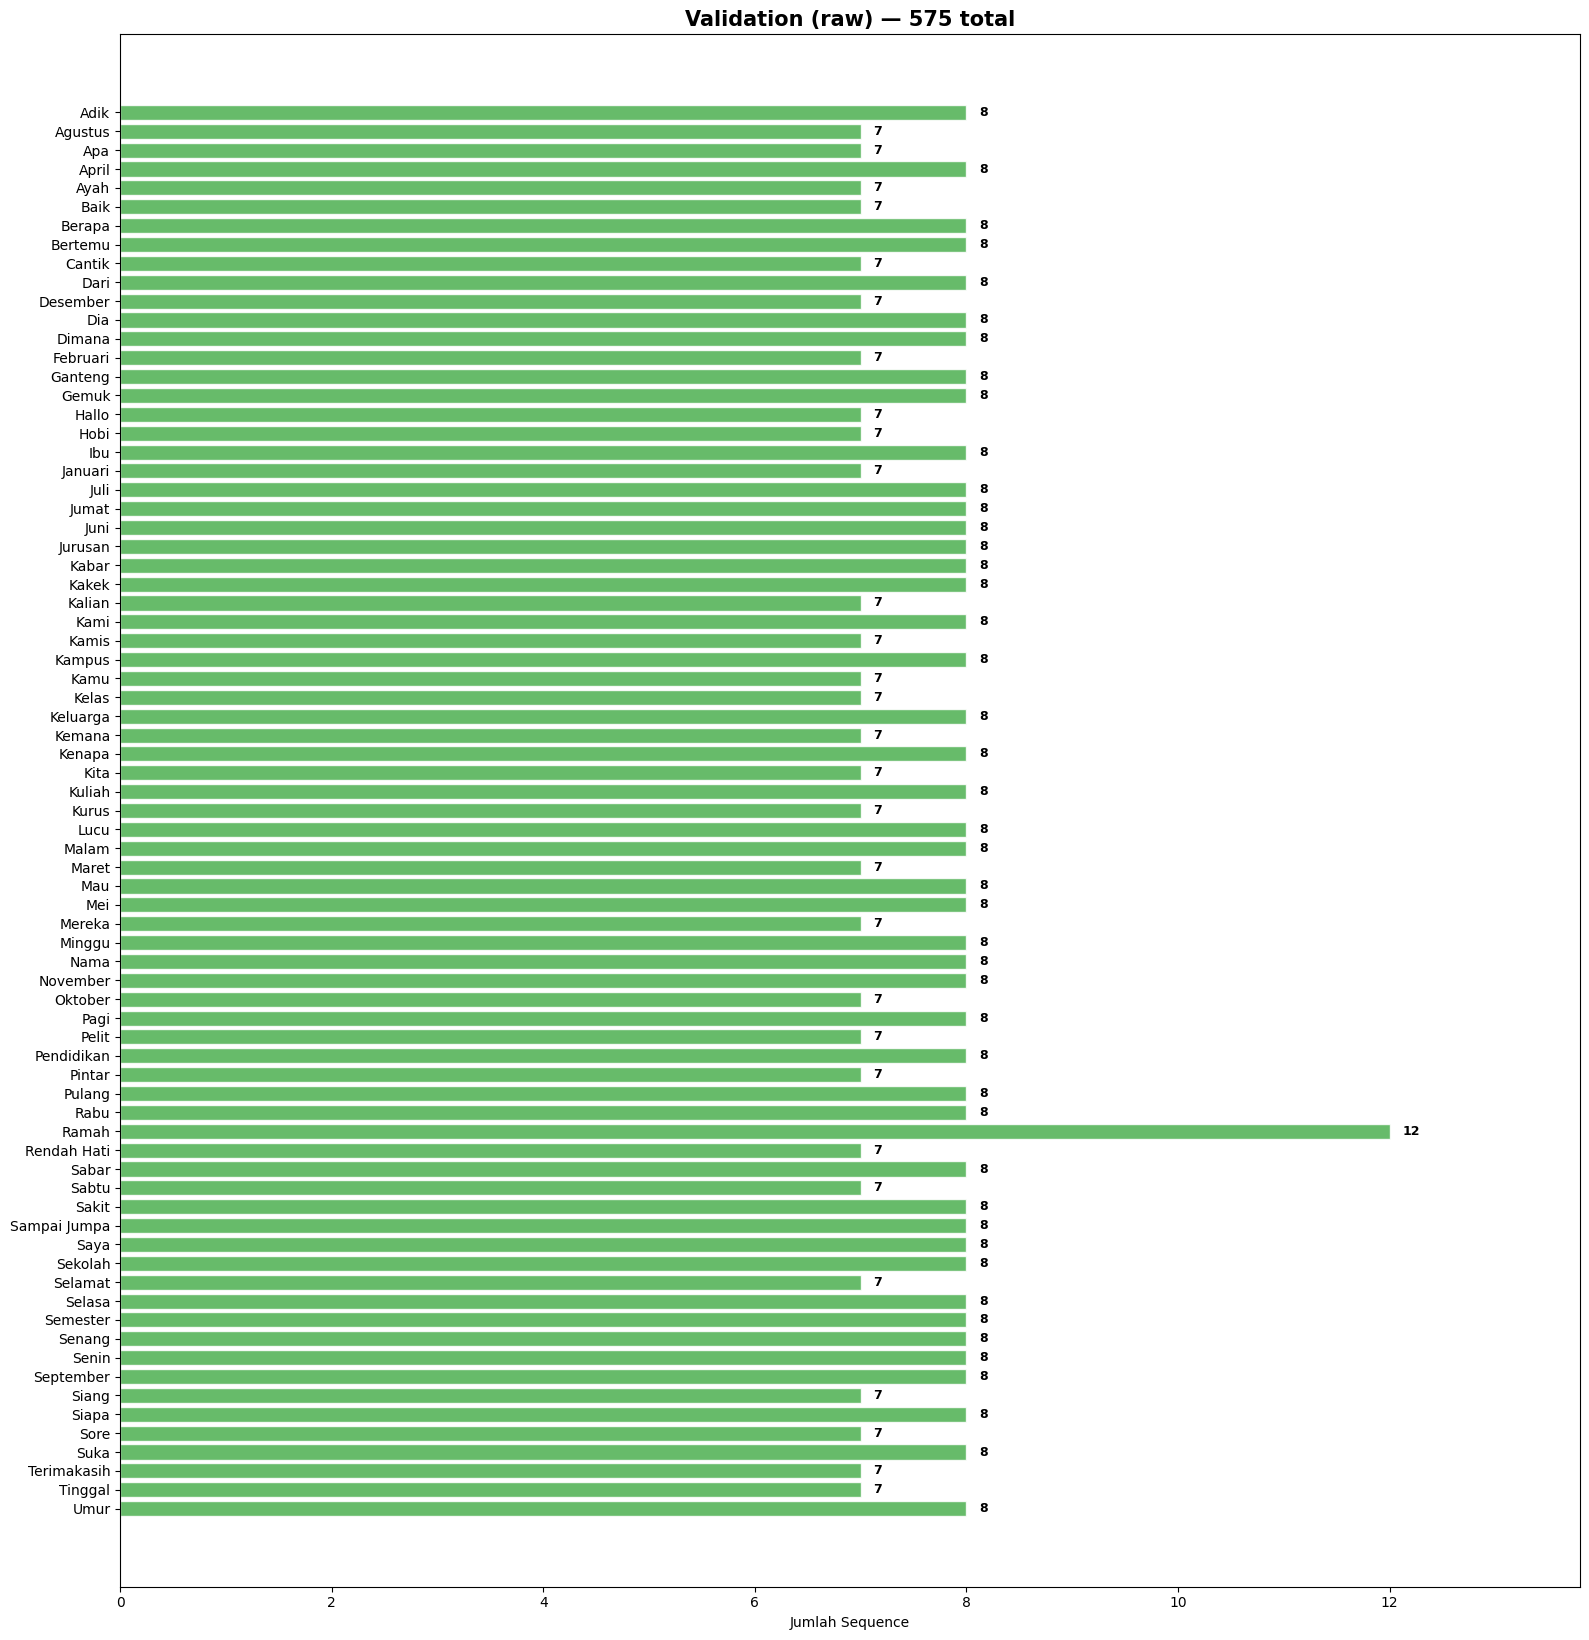

In [9]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

counts = np.sum(y_val, axis=0).astype(int)
bars = ax.barh(actions, counts, color='#4CAF50', alpha=0.85, edgecolor='white')
ax.set_title(f'Validation (raw) — {y_val.shape[0]} total', fontweight='bold', fontsize=15)
ax.set_xlabel('Jumlah Sequence')
ax.set_xlim(0, max(counts) * 1.15)
ax.invert_yaxis()

for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2,
            str(c), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_val.png', dpi=200, bbox_inches='tight')
plt.show()

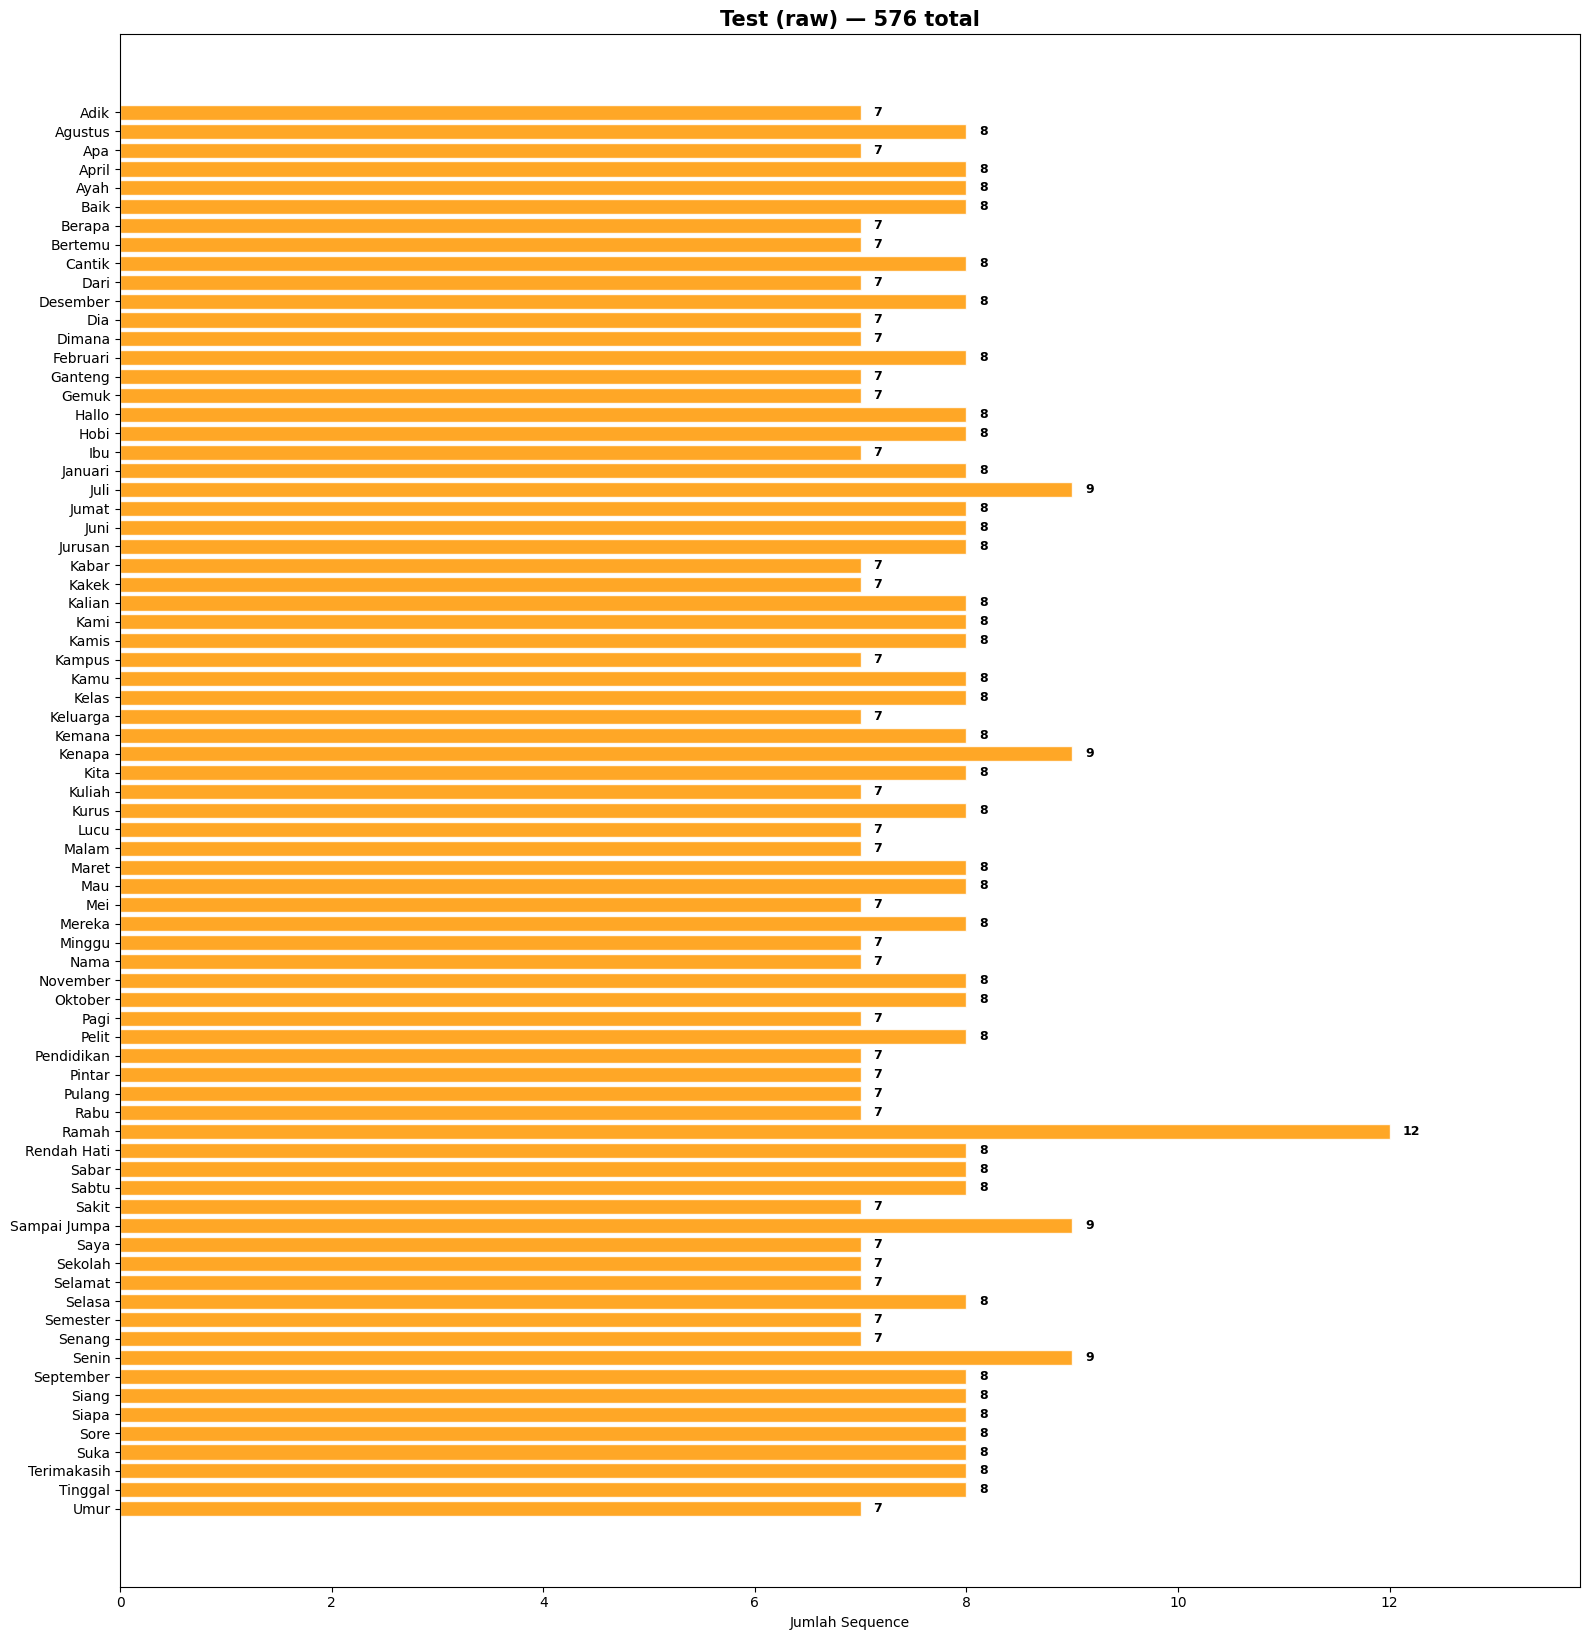

In [10]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

counts = np.sum(y_test, axis=0).astype(int)
bars = ax.barh(actions, counts, color='#FF9800', alpha=0.85, edgecolor='white')
ax.set_title(f'Test (raw) — {y_test.shape[0]} total', fontweight='bold', fontsize=15)
ax.set_xlabel('Jumlah Sequence')
ax.set_xlim(0, max(counts) * 1.15)
ax.invert_yaxis()

for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2,
            str(c), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_test.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
class AttentionLayer(Layer):
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(shape=(input_shape[1], 1),
                                 initializer='zeros', trainable=True)
        super().build(input_shape)

    def call(self, x):
        e = tf.nn.tanh(tf.matmul(x, self.W) + self.b)
        a = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(x * a, axis=1)

    def get_config(self):
        return super().get_config()

@tf.keras.utils.register_keras_serializable(package='custom')
class FocalLossWithSmoothing(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 name='focal_loss_with_smoothing', **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma
        self.alpha = alpha if alpha is not None else [1.0] * 25
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        n_classes = tf.shape(y_pred)[-1]
        # Label smoothing
        y_true_smooth = y_true * (1.0 - self.label_smoothing) + \
                        self.label_smoothing / tf.cast(n_classes, tf.float32)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true_smooth * tf.math.log(y_pred)

        alpha_tensor = tf.constant(self.alpha, dtype=tf.float32)
        pt = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        alpha_w = tf.reduce_sum(y_true * alpha_tensor, axis=-1, keepdims=True)
        focal_w = alpha_w * tf.pow(1.0 - pt, self.gamma)
        return tf.reduce_mean(focal_w * ce)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            'gamma': self.gamma,
            'alpha': self.alpha,
            'label_smoothing': self.label_smoothing,
        })
        return cfg


def build_model(seq_len, n_features, n_classes):
    inputs = Input(shape=(seq_len, n_features))

    # Input noise ringan → regularisasi tambahan
    x = GaussianNoise(0.005)(inputs)

    # BiLSTM
    x = Bidirectional(LSTM(96, return_sequences=True,
                           kernel_regularizer=l2(0.001),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Bidirectional(LSTM(64, return_sequences=True,
                           kernel_regularizer=l2(0.001),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = AttentionLayer()(x)

    # Dense
    x = Dense(192, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Dense(96, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = Dropout(0.3)(x)

    x = Dense(48, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = Dropout(0.2)(x)

    outputs = Dense(n_classes, activation='softmax')(x)
    return Model(inputs, outputs, name='BiLSTM_Attention_SIBI_25class_v2')

FOCAL_ALPHA = [1.0] * len(actions)  # uniform, confusable-class weighting tidak dipakai untuk saat ini

model = build_model(sequence_length, FITUR_PER_FRAME, len(actions))
model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss=FocalLossWithSmoothing(gamma=2.0, alpha=FOCAL_ALPHA, label_smoothing=0.05),
    metrics=['accuracy']
)
model.summary()

with open(f'{PATH_CONFIGURATION_GENERAL}/model_summary.txt', 'w', encoding='utf-8') as f:
    model.summary(print_fn=lambda x: f.write(x + '\n'))
print("✅ Model summary tersimpan : model_summary.txt")

I0000 00:00:1789527097.341988   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1789527097.345381   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1789527097.345423   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1789527097.585893   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1789527097.585998   47745 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-16

Model: "BiLSTM_Attention_SIBI_25class_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 30, 192)        │       272,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 192)        │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 192)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 30, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ (None, 128)            │           158 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 192)            │        24,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 192)            │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 96)             │        18,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 48)             │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 75)             │         3,675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 458,057 (1.75 MB)

 Trainable params: 457,033 (1.74 MB)

 Non-trainable params: 1,024 (4.00 KB)

✅ Model summary tersimpan : model_summary.txt


In [12]:
import tensorflow as tf

checkpoint = ModelCheckpoint(
    TEMP_CHECKPOINT,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=60,
    min_delta=1e-4,
    restore_best_weights=True,
    mode='min',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=15,
    min_lr=1e-6,
    mode='min',
    verbose=1
)


class PerClassAccuracyCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, y_val, actions, every_n=10):
        self.X_val   = X_val
        self.y_val   = y_val
        self.actions = actions
        self.every_n = every_n
        self.best_per_class = {a: 0.0 for a in actions}

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n != 0:
            return
        y_pred = np.argmax(self.model.predict(self.X_val, verbose=0), axis=1)
        y_true = np.argmax(self.y_val, axis=1)
        print(f'\n  [Epoch {epoch+1}] Per-class val accuracy:')
        for i, action in enumerate(self.actions):
            mask = (y_true == i)
            if mask.sum() == 0:
                continue
            acc_i = (y_pred[mask] == i).mean()
            if acc_i > self.best_per_class[action]:
                self.best_per_class[action] = acc_i
            flag = ' ⚠️ ' if acc_i < 0.85 else ''
            print(f'    {action:12s}: {acc_i*100:5.1f}% (best {self.best_per_class[action]*100:5.1f}%){flag}')



per_class_cb = PerClassAccuracyCallback(X_val, y_val, actions, every_n=10)

print('Memulai training...\n')
print('Catatan: training TIDAK pakai class_weight lagi → cegah double weighting')
print('         dengan focal alpha. Loss yang dipakai sudah handle imbalance.\n')

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOCHS,
    batch_size=64,
    callbacks=[early_stop, checkpoint, reduce_lr, per_class_cb],
    verbose=1,
    shuffle=True,
)

best_model = tf.keras.models.load_model(
    TEMP_CHECKPOINT,
    custom_objects={'AttentionLayer': AttentionLayer,
                    'FocalLossWithSmoothing': FocalLossWithSmoothing}
)

best_model.save(MODEL_OUTPUT)
best_model.save(MODEL_OUTPUT_H5)

if os.path.exists(TEMP_CHECKPOINT):
    os.remove(TEMP_CHECKPOINT)

print(f'\n✅ Model terbaik disimpan : {MODEL_OUTPUT}')
print(f'✅ Model tersimpan (.h5)    : {MODEL_OUTPUT_H5}')
print(f'   Total epoch berjalan   : {len(history.history["loss"])}')
print(f'   Val loss terbaik       : {min(history.history["val_loss"]):.4f}')
print(f'   Val accuracy terbaik   : {max(history.history["val_accuracy"])*100:.2f}%')
print(f'   Epoch terbaik (val_loss) : {np.argmin(history.history["val_loss"]) + 1}')

Memulai training...

Catatan: training TIDAK pakai class_weight lagi → cegah double weighting
         dengan focal alpha. Loss yang dipakai sudah handle imbalance.

Epoch 1/500


2026-09-16 09:52:07.564961: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907


293/294 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0425 - loss: 0.8063
Epoch 1: val_loss improved from None to 0.09982, saving model to Epoch500_20260916_093550/temp_checkpoint.keras
294/294 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.0744 - loss: 0.4471 - val_accuracy: 0.0313 - val_loss: 0.0998 - learning_rate: 5.0000e-04
Epoch 2/500
293/294 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1469 - loss: 0.0667
Epoch 2: val_loss improved from 0.09982 to 0.05975, saving model to Epoch500_20260916_093550/temp_checkpoint.keras
294/294 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.1662 - loss: 0.0552 - val_accuracy: 0.0574 - val_loss: 0.0598 - learning_rate: 5.0000e-04
Epoch 3/500
293/294 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2123 - loss: 0.0404
Epoch 3: val_loss improved from 0.05975 to 0.05388, saving model to Epoch500_20260916_093550/temp_checkpoint.keras
294/294 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.2353 - loss: 0.0386 - val_accuracy: 0.0835 - val_loss: 0.


✅ Model terbaik disimpan : Epoch500_20260916_093550/model25class.keras
✅ Model tersimpan (.h5)    : Epoch500_20260916_093550/model25class.h5
   Total epoch berjalan   : 247
   Val loss terbaik       : 0.0031
   Val accuracy terbaik   : 96.00%
   Epoch terbaik (val_loss) : 187


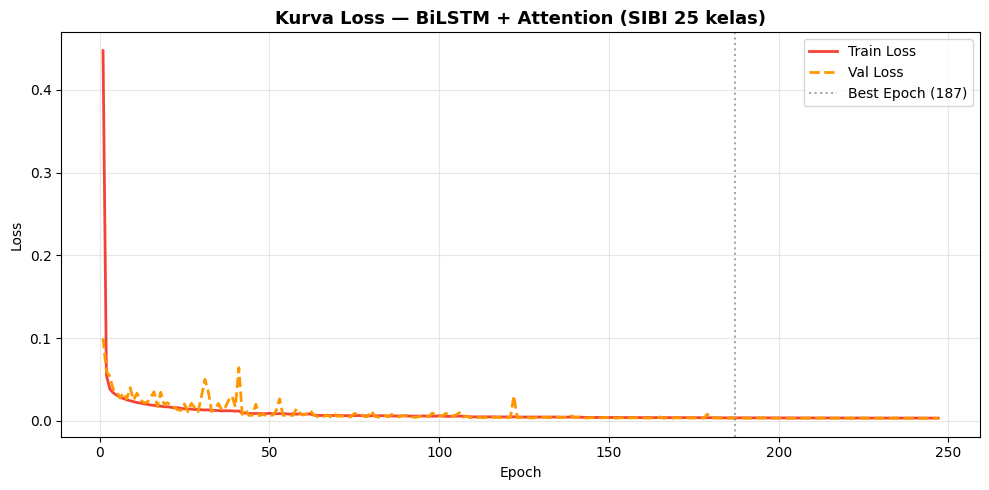

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
epochs_range = range(1, len(history.history['loss']) + 1)

ax.plot(epochs_range, history.history['loss'],
        color='#F44336', linewidth=2, label='Train Loss')
ax.plot(epochs_range, history.history['val_loss'],
        color='#FF9800', linewidth=2, linestyle='--', label='Val Loss')
best_ep = np.argmin(history.history['val_loss']) + 1
ax.axvline(x=best_ep, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep})')
ax.set_title('Kurva Loss — BiLSTM + Attention (SIBI 25 kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_loss.png', dpi=150, bbox_inches='tight')
plt.show()

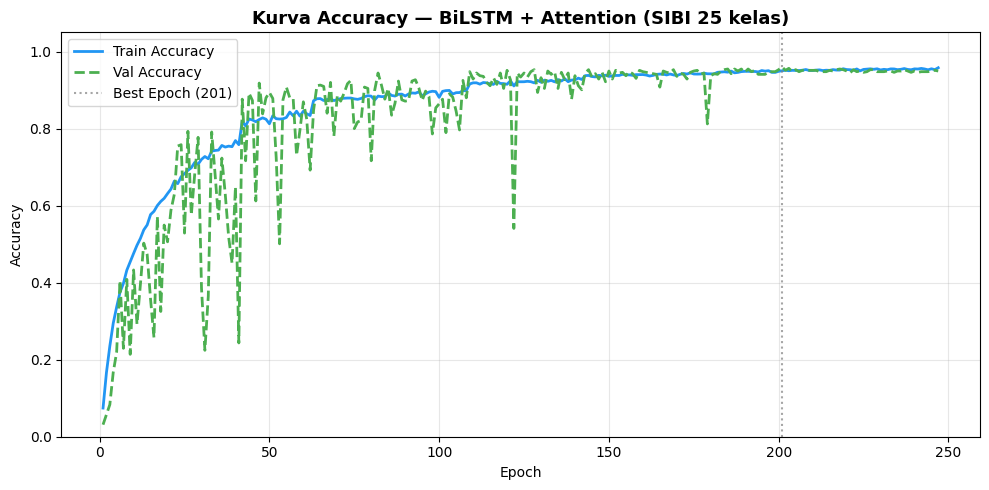

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(epochs_range, history.history['accuracy'],
        color='#2196F3', linewidth=2, label='Train Accuracy')
ax.plot(epochs_range, history.history['val_accuracy'],
        color='#4CAF50', linewidth=2, linestyle='--', label='Val Accuracy')
best_ep_acc = np.argmax(history.history['val_accuracy']) + 1
ax.axvline(x=best_ep_acc, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep_acc})')
ax.set_title('Kurva Accuracy — BiLSTM + Attention (SIBI 25 kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

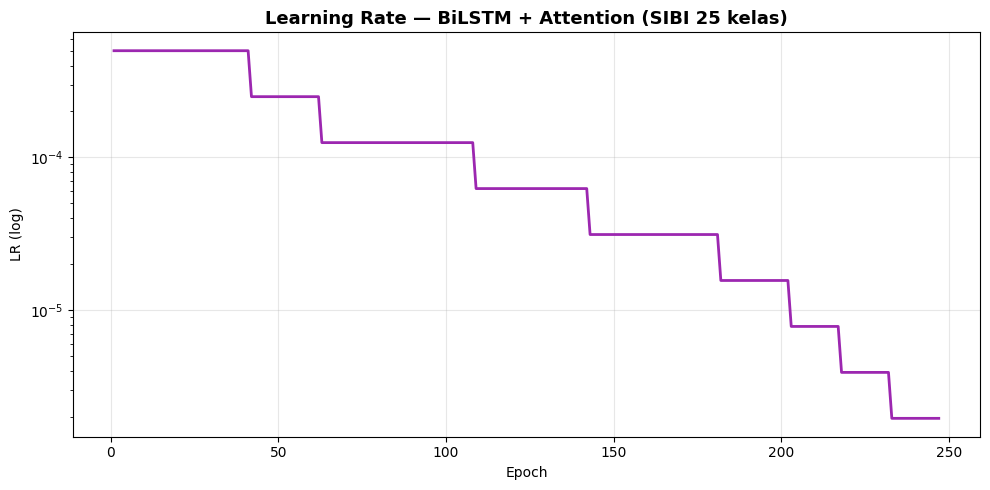

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

if 'learning_rate' in history.history:
    ax.plot(epochs_range, history.history['learning_rate'],
            color='#9C27B0', linewidth=2)
    ax.set_yscale('log')
    ax.set_title('Learning Rate — BiLSTM + Attention (SIBI 25 kelas)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR (log)')
    ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'LR history\ntidak tersedia',
            ha='center', va='center', transform=ax.transAxes)
    ax.set_title('Learning Rate', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_learning_rate.png', dpi=150, bbox_inches='tight')
plt.show()

In [28]:
loss, acc = best_model.evaluate(X_test, y_test, verbose=0)
print('=' * 50)
print(f'  TEST ACCURACY : {acc * 100:.2f}%')
print(f'  TEST LOSS     : {loss:.4f}')
print('=' * 50)

y_pred_prob = best_model.predict(X_test, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = np.argmax(y_test,      axis=1)

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=actions))

report_str = classification_report(y_true, y_pred, target_names=actions)
with open(f'{PATH_CONFIGURATION_GENERAL}/classification_report.txt', 'w') as f:
    f.write(f"Test Accuracy : {acc*100:.2f}%\n")
    f.write(f"Test Loss     : {loss:.4f}\n\n")
    f.write(report_str)
print("✅ Classification report tersimpan")

  TEST ACCURACY : 97.05%
  TEST LOSS     : 0.0030

Classification Report:
              precision    recall  f1-score   support

        Adik       1.00      1.00      1.00         7
     Agustus       0.86      0.75      0.80         8
         Apa       1.00      1.00      1.00         7
       April       0.58      0.88      0.70         8
        Ayah       1.00      0.88      0.93         8
        Baik       1.00      1.00      1.00         8
      Berapa       1.00      1.00      1.00         7
     Bertemu       1.00      1.00      1.00         7
      Cantik       0.89      1.00      0.94         8
        Dari       1.00      1.00      1.00         7
    Desember       1.00      1.00      1.00         8
         Dia       1.00      0.86      0.92         7
      Dimana       1.00      1.00      1.00         7
    Februari       1.00      1.00      1.00         8
     Ganteng       1.00      0.86      0.92         7
       Gemuk       1.00      1.00      1.00         7
       

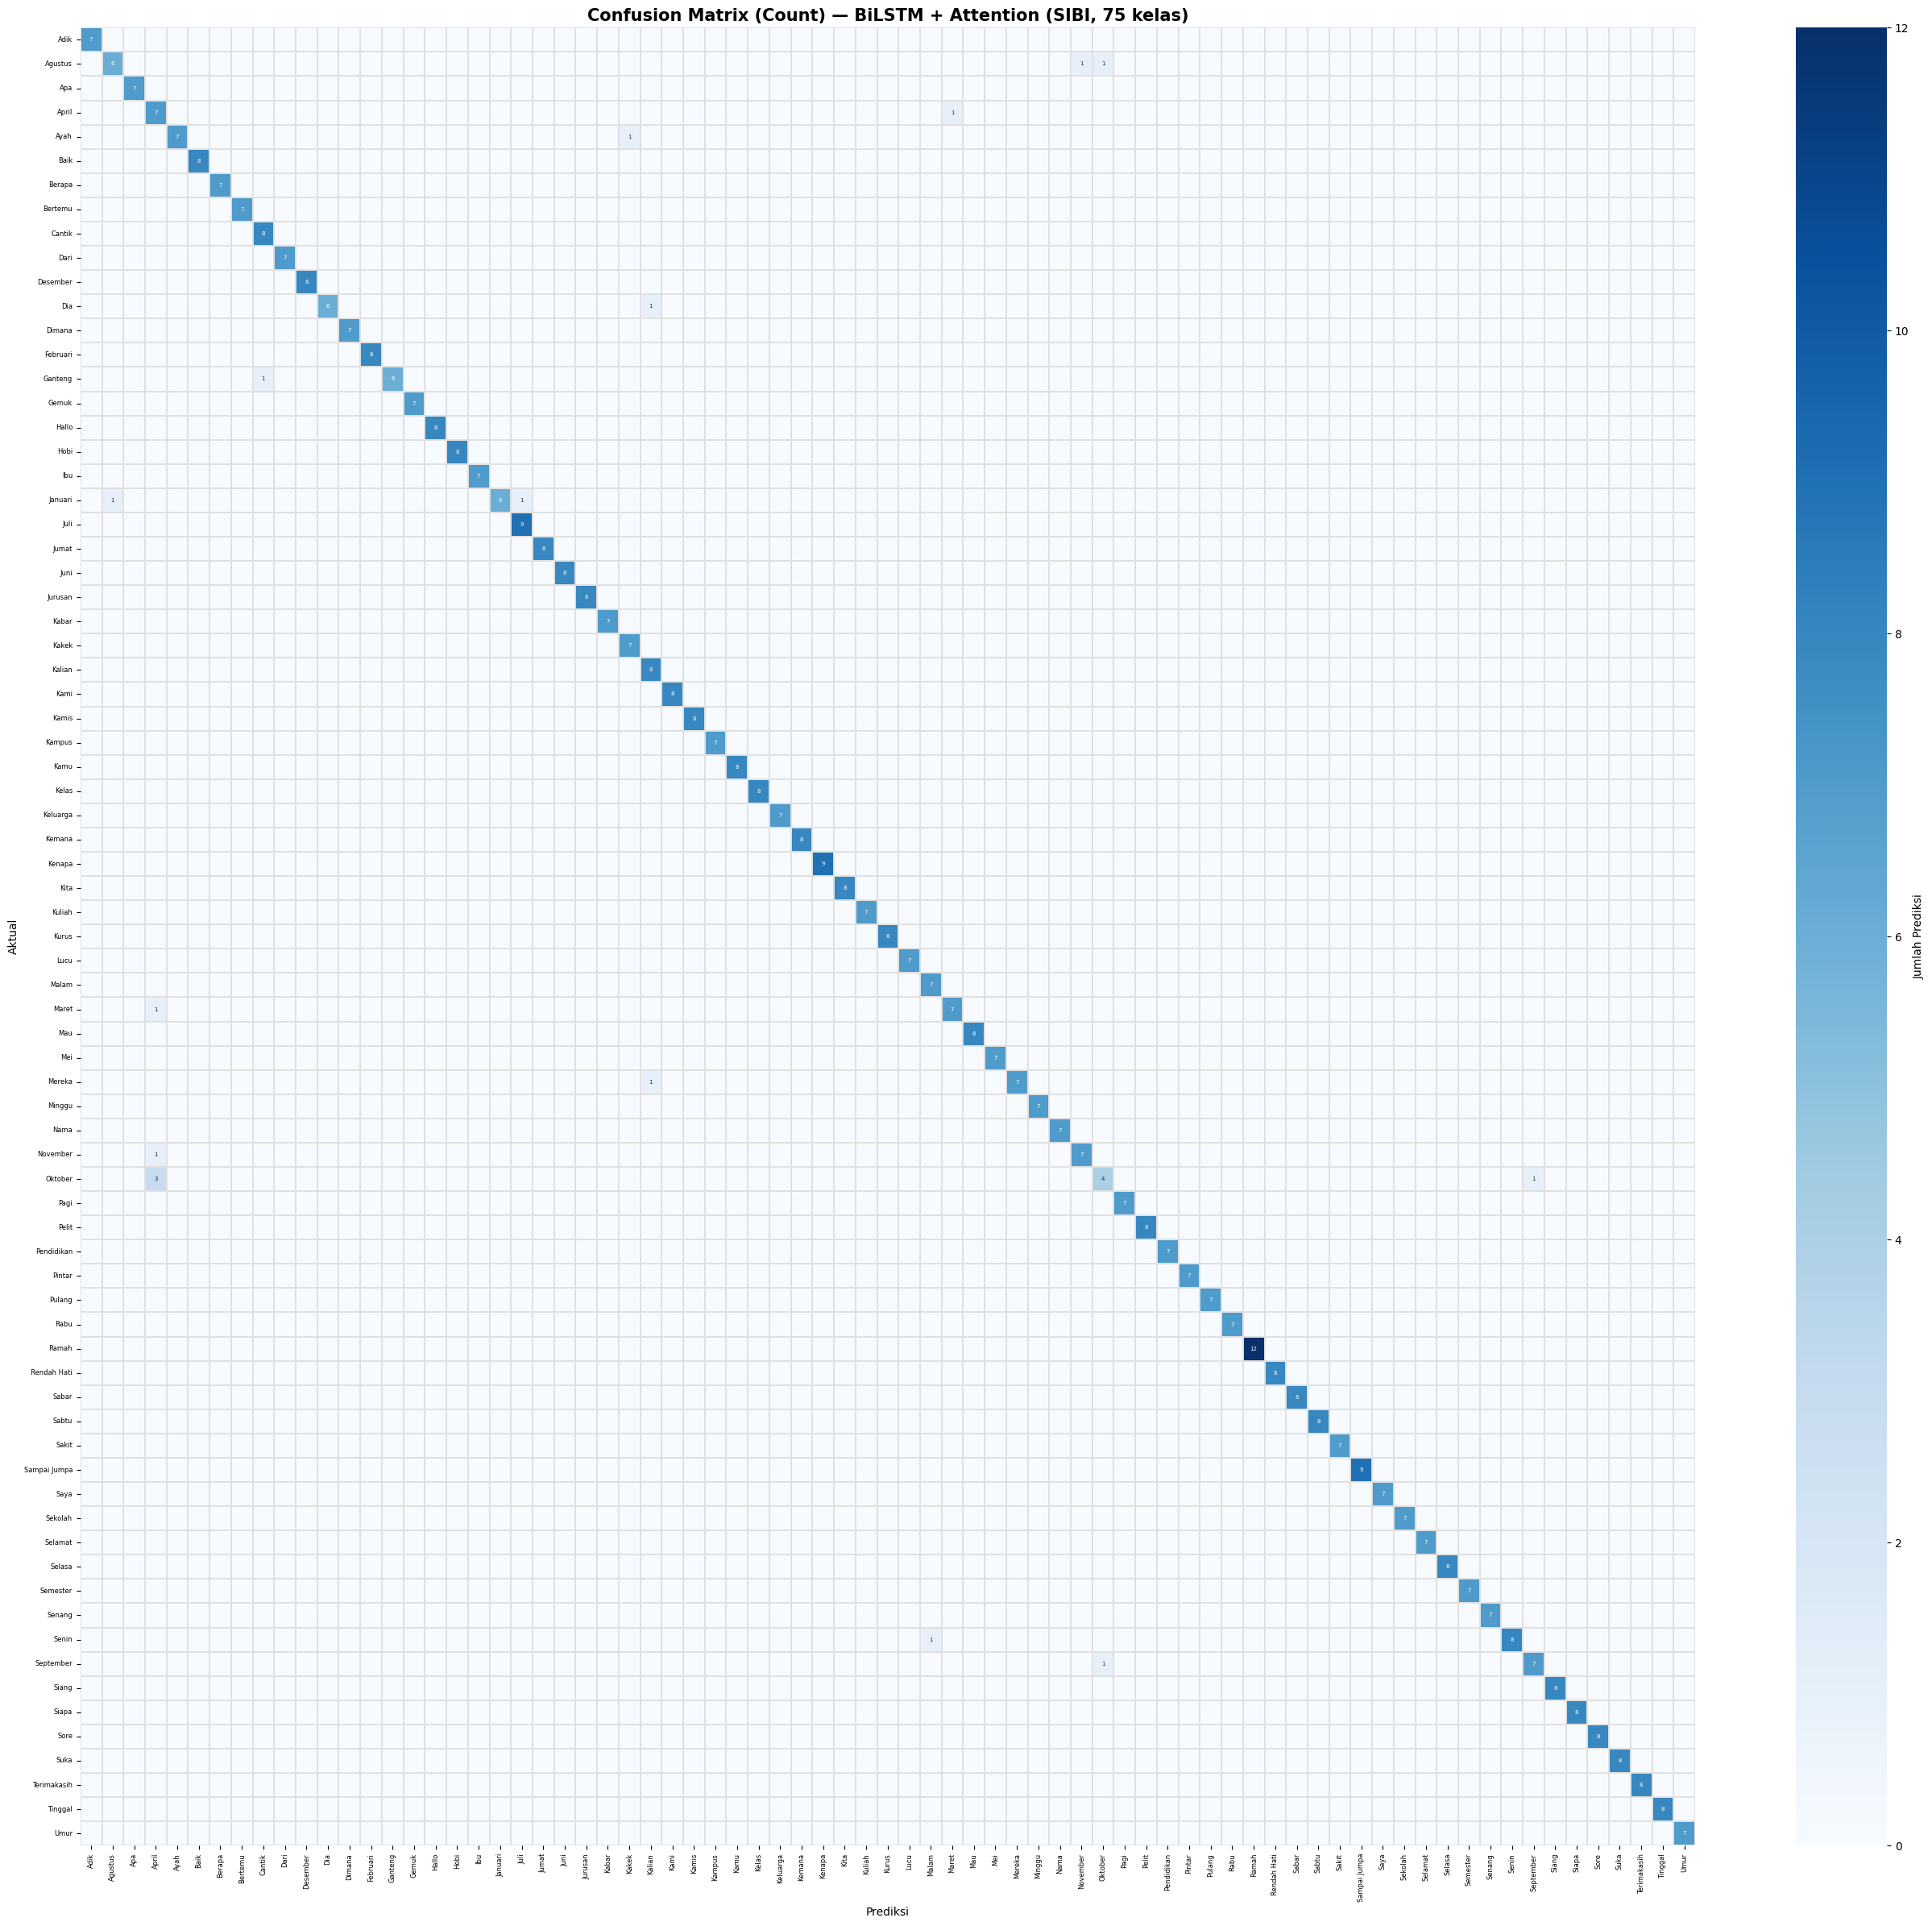

In [17]:
n = len(actions)
cm = confusion_matrix(y_true, y_pred)

# Untuk kelas banyak, sembunyikan angka di sel bernilai 0 (mayoritas sel memang kosong)
if n > 30:
    annot_labels = np.where(cm == 0, '', cm.astype(str))
    annot_fmt = ''
else:
    annot_labels = True
    annot_fmt = 'd'

fig, ax = plt.subplots(figsize=(max(14, n * 0.35), max(12, n * 0.32)))
sns.heatmap(cm, annot=annot_labels, fmt=annot_fmt, cmap='Blues',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.3, linecolor='#E0E0E0',
            annot_kws={'fontsize': max(5, min(9, 350 / n))},
            cbar_kws={'label': 'Jumlah Prediksi'})

ax.set_title(f'Confusion Matrix (Count) — BiLSTM + Attention (SIBI, {n} kelas)',
             fontweight='bold', fontsize=15)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')

tick_fontsize = max(6, min(10, 400 / n))
plt.xticks(rotation=90, ha='center', fontsize=tick_fontsize)
plt.yticks(rotation=0, fontsize=tick_fontsize)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_count.png', dpi=250, bbox_inches='tight')
plt.show()

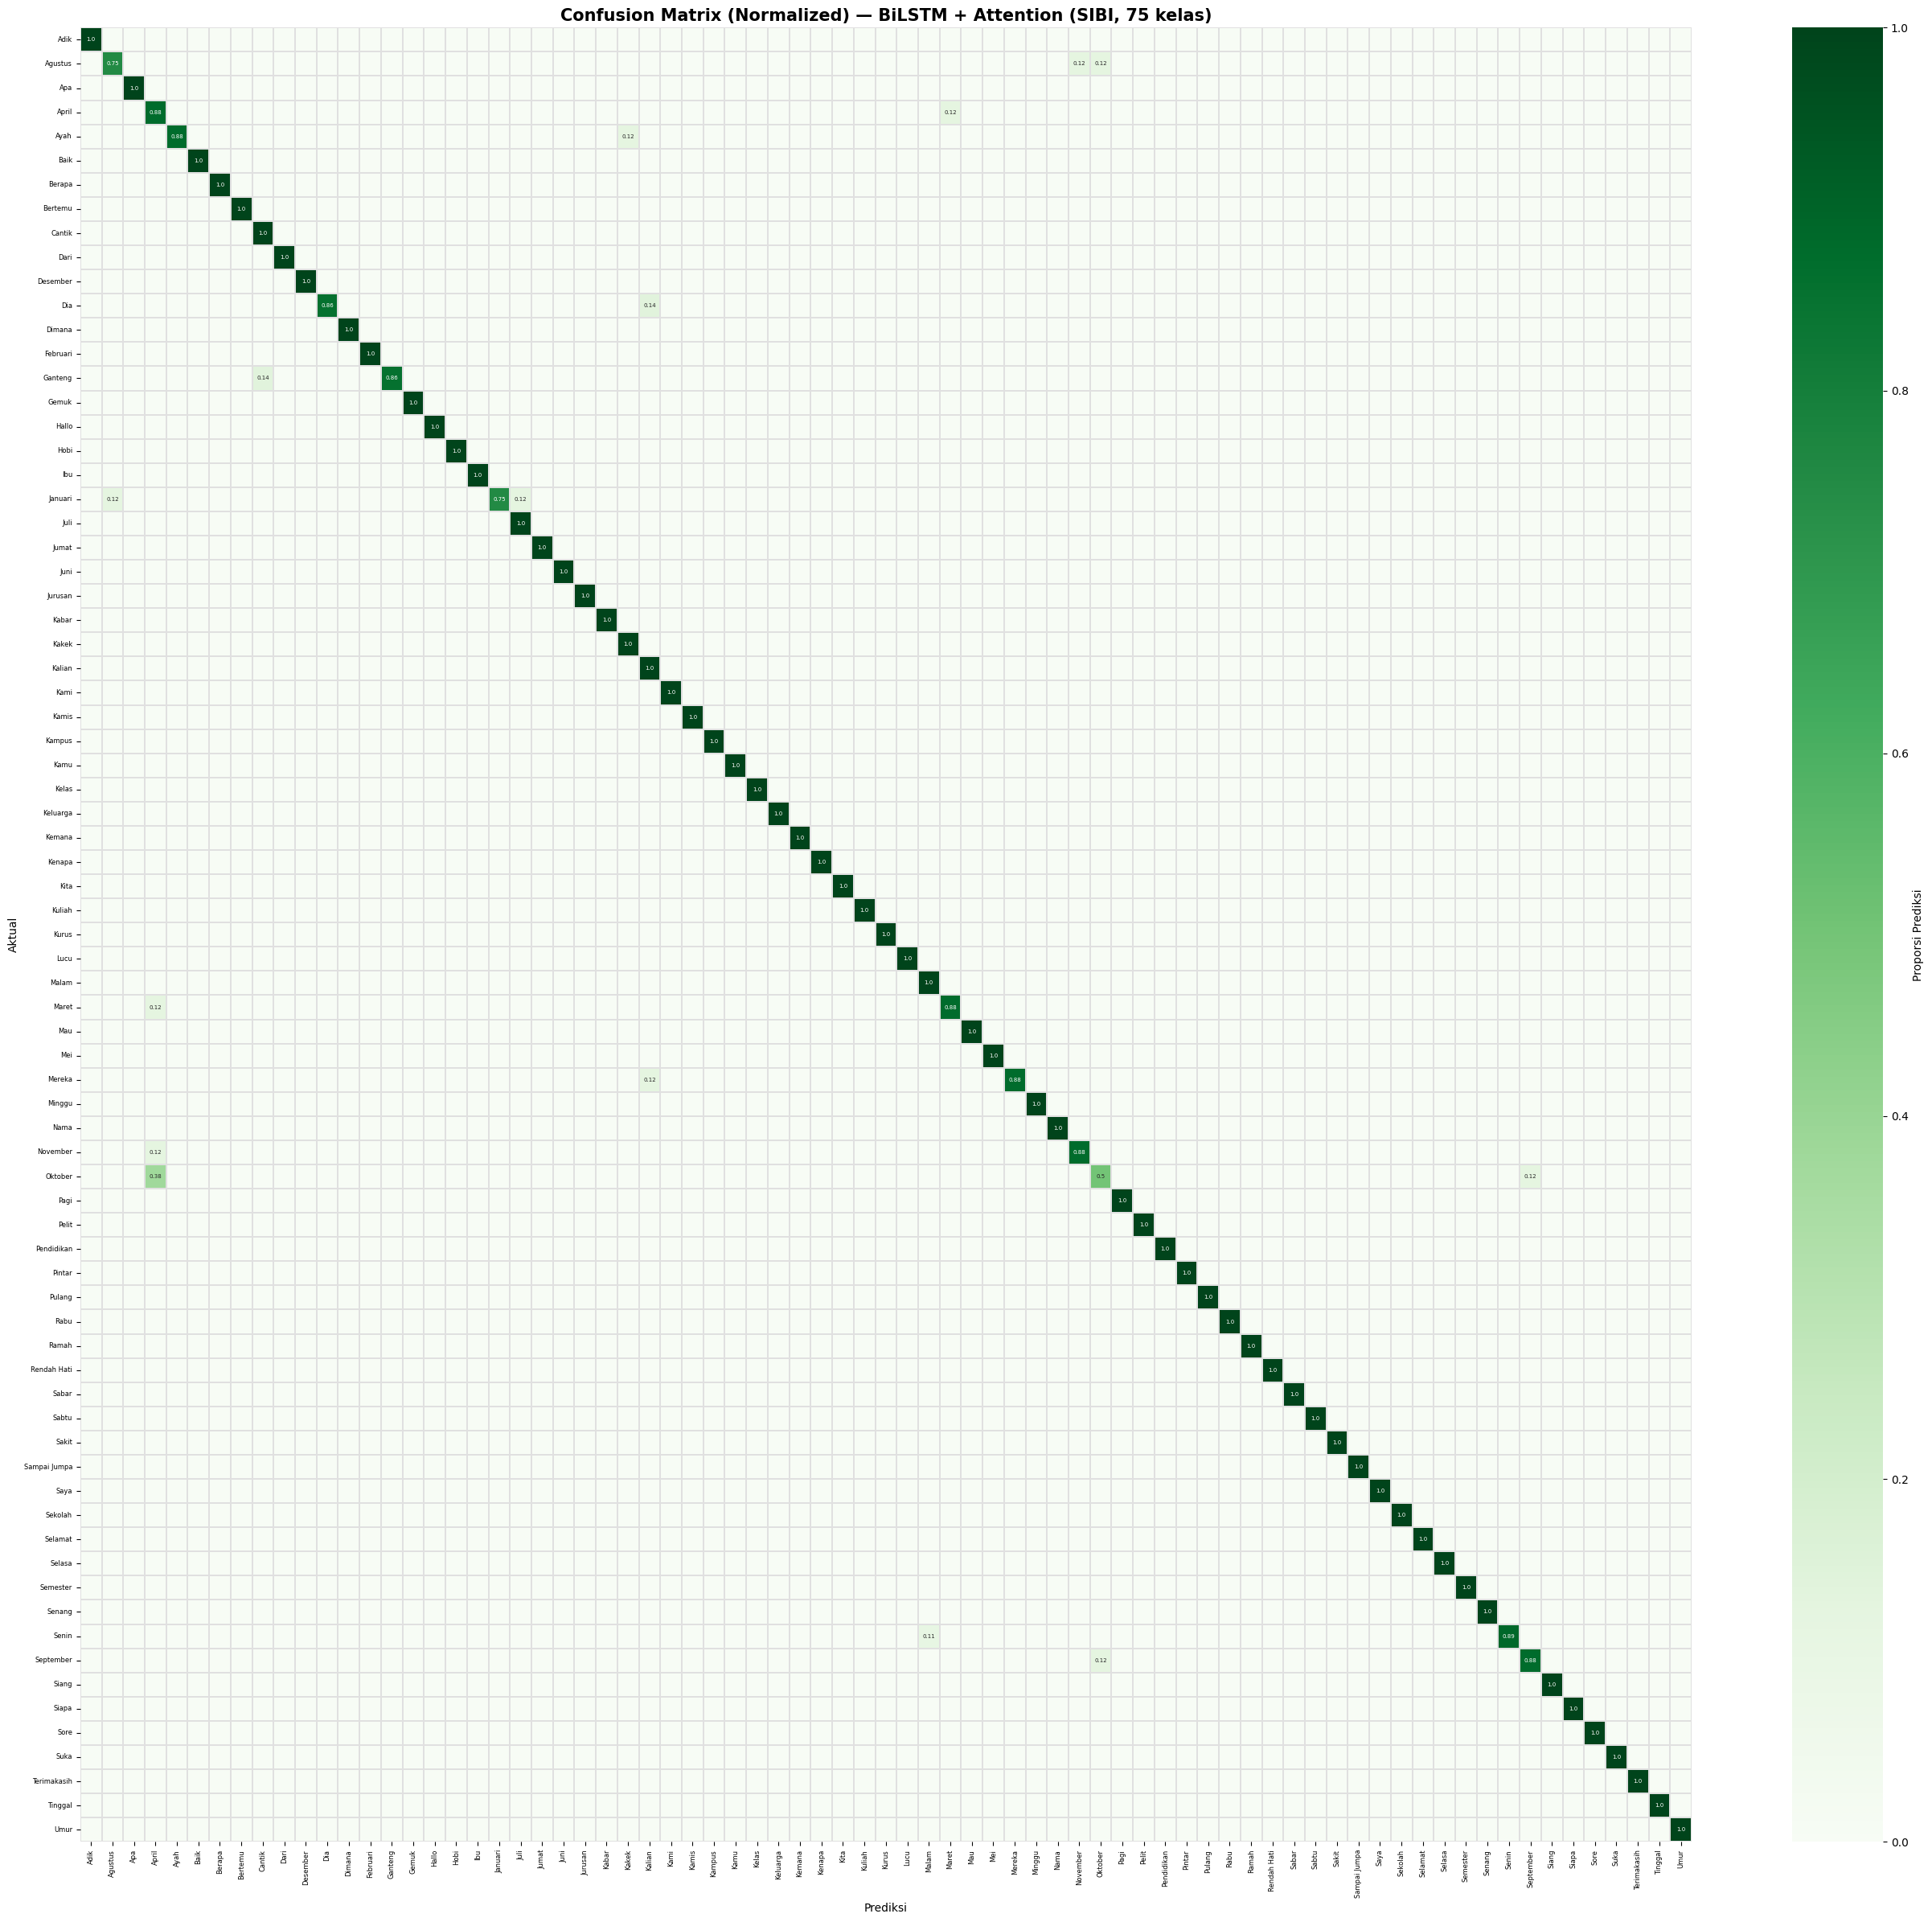

In [18]:
n = len(actions)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Untuk kelas banyak, sembunyikan angka di sel bernilai 0 (mayoritas sel memang kosong)
if n > 30:
    annot_labels = np.where(cm_norm == 0, '', np.round(cm_norm, 2).astype(str))
    annot_fmt = ''
else:
    annot_labels = True
    annot_fmt = '.2f'

fig, ax = plt.subplots(figsize=(max(14, n * 0.35), max(12, n * 0.32)))
sns.heatmap(cm_norm, annot=annot_labels, fmt=annot_fmt, cmap='Greens',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.3, linecolor='#E0E0E0', vmin=0, vmax=1,
            annot_kws={'fontsize': max(5, min(9, 350 / n))},
            cbar_kws={'label': 'Proporsi Prediksi'})

ax.set_title(f'Confusion Matrix (Normalized) — BiLSTM + Attention (SIBI, {n} kelas)',
             fontweight='bold', fontsize=15)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')

tick_fontsize = max(6, min(10, 400 / n))
plt.xticks(rotation=90, ha='center', fontsize=tick_fontsize)
plt.yticks(rotation=0, fontsize=tick_fontsize)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_normalized.png', dpi=250, bbox_inches='tight')
plt.show()

In [19]:
print('\n⚠️  Confusable Pairs:')
for i in range(len(actions)):
    for j in range(len(actions)):
        if i != j and cm[i][j] > 0:
            print(f'  {actions[i]} → diprediksi {actions[j]}: {cm[i][j]} kali')


⚠️  Confusable Pairs:
  Agustus → diprediksi November: 1 kali
  Agustus → diprediksi Oktober: 1 kali
  April → diprediksi Maret: 1 kali
  Ayah → diprediksi Kakek: 1 kali
  Dia → diprediksi Kalian: 1 kali
  Ganteng → diprediksi Cantik: 1 kali
  Januari → diprediksi Agustus: 1 kali
  Januari → diprediksi Juli: 1 kali
  Maret → diprediksi April: 1 kali
  Mereka → diprediksi Kalian: 1 kali
  November → diprediksi April: 1 kali
  Oktober → diprediksi April: 3 kali
  Oktober → diprediksi September: 1 kali
  Senin → diprediksi Malam: 1 kali
  September → diprediksi Oktober: 1 kali


In [20]:
report    = classification_report(y_true, y_pred,
                                   target_names=actions, output_dict=True)
df_report = pd.DataFrame(report).transpose().loc[actions]

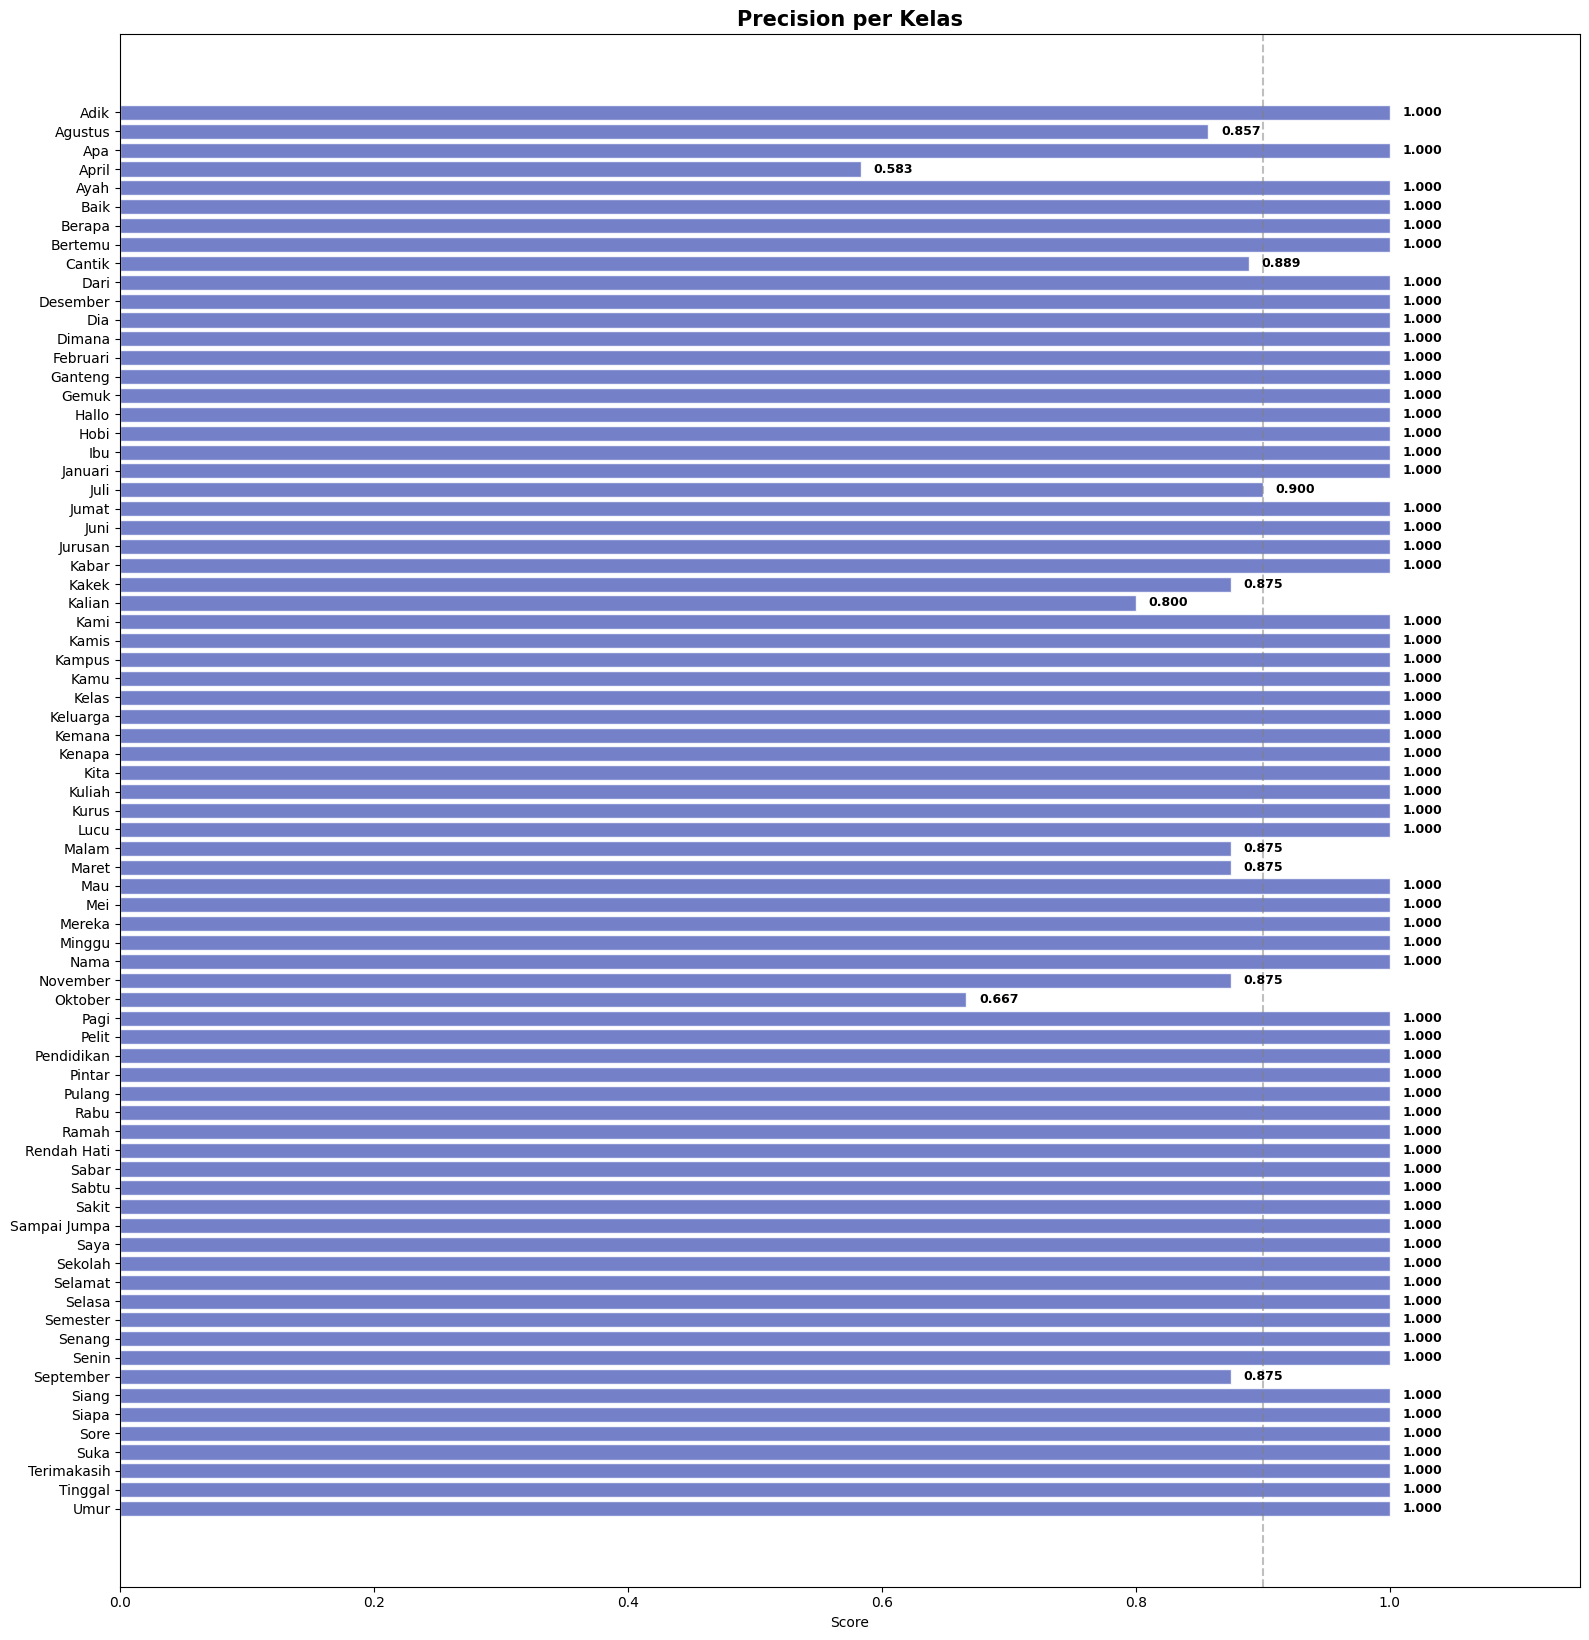

In [21]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

vals = df_report['precision'].values
bars = ax.barh(actions, vals, color='#5C6BC0', alpha=0.85, edgecolor='white')
ax.set_title('Precision per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Score')
ax.set_xlim(0, 1.15)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5)
ax.invert_yaxis()

for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_precision.png', dpi=200, bbox_inches='tight')
plt.show()

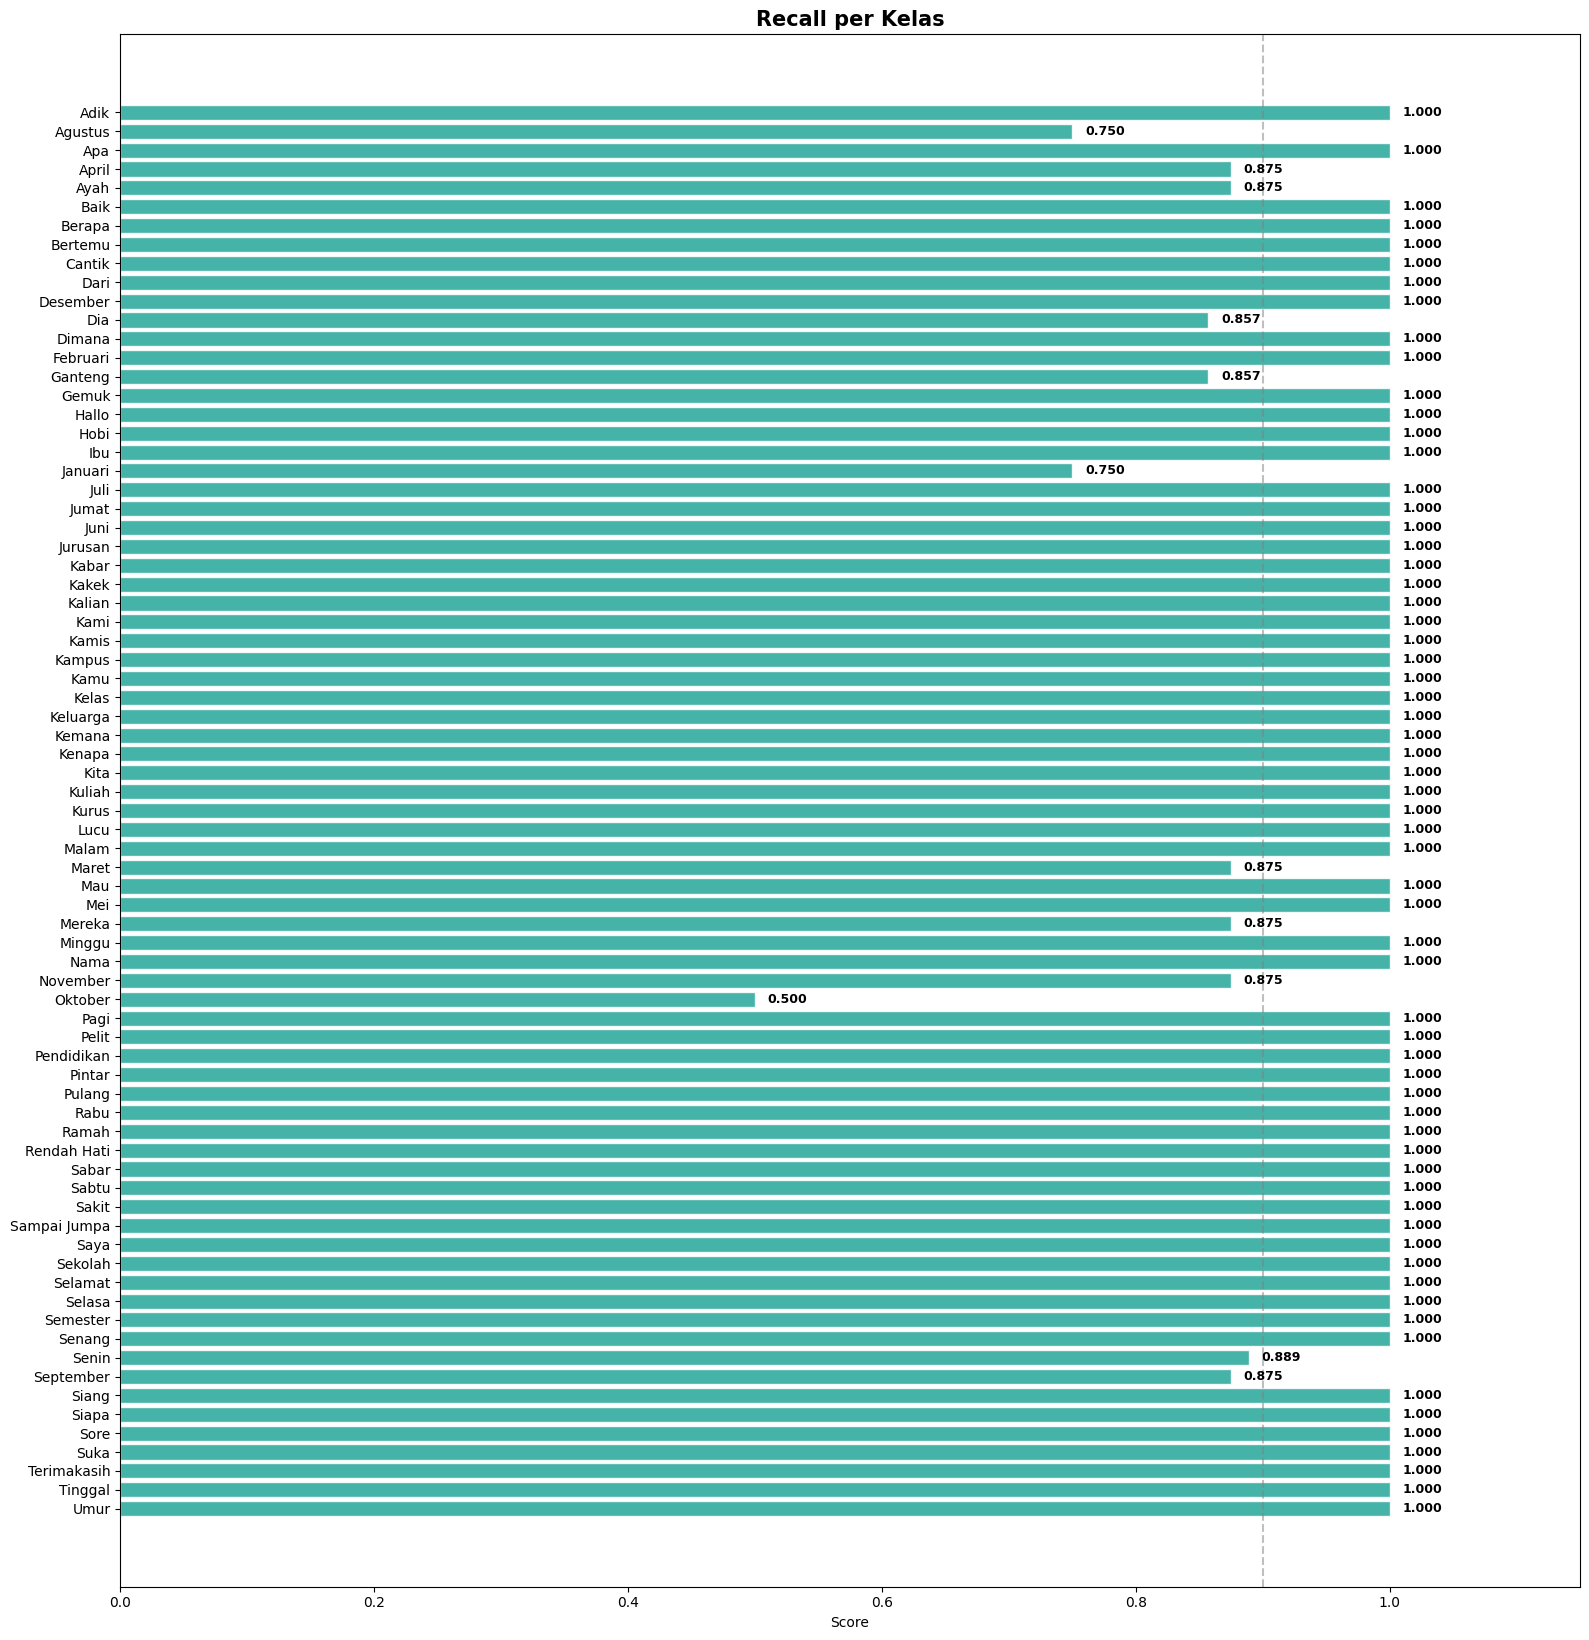

In [22]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

vals = df_report['recall'].values
bars = ax.barh(actions, vals, color='#26A69A', alpha=0.85, edgecolor='white')
ax.set_title('Recall per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Score')
ax.set_xlim(0, 1.15)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5)
ax.invert_yaxis()

for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_recall.png', dpi=200, bbox_inches='tight')
plt.show()

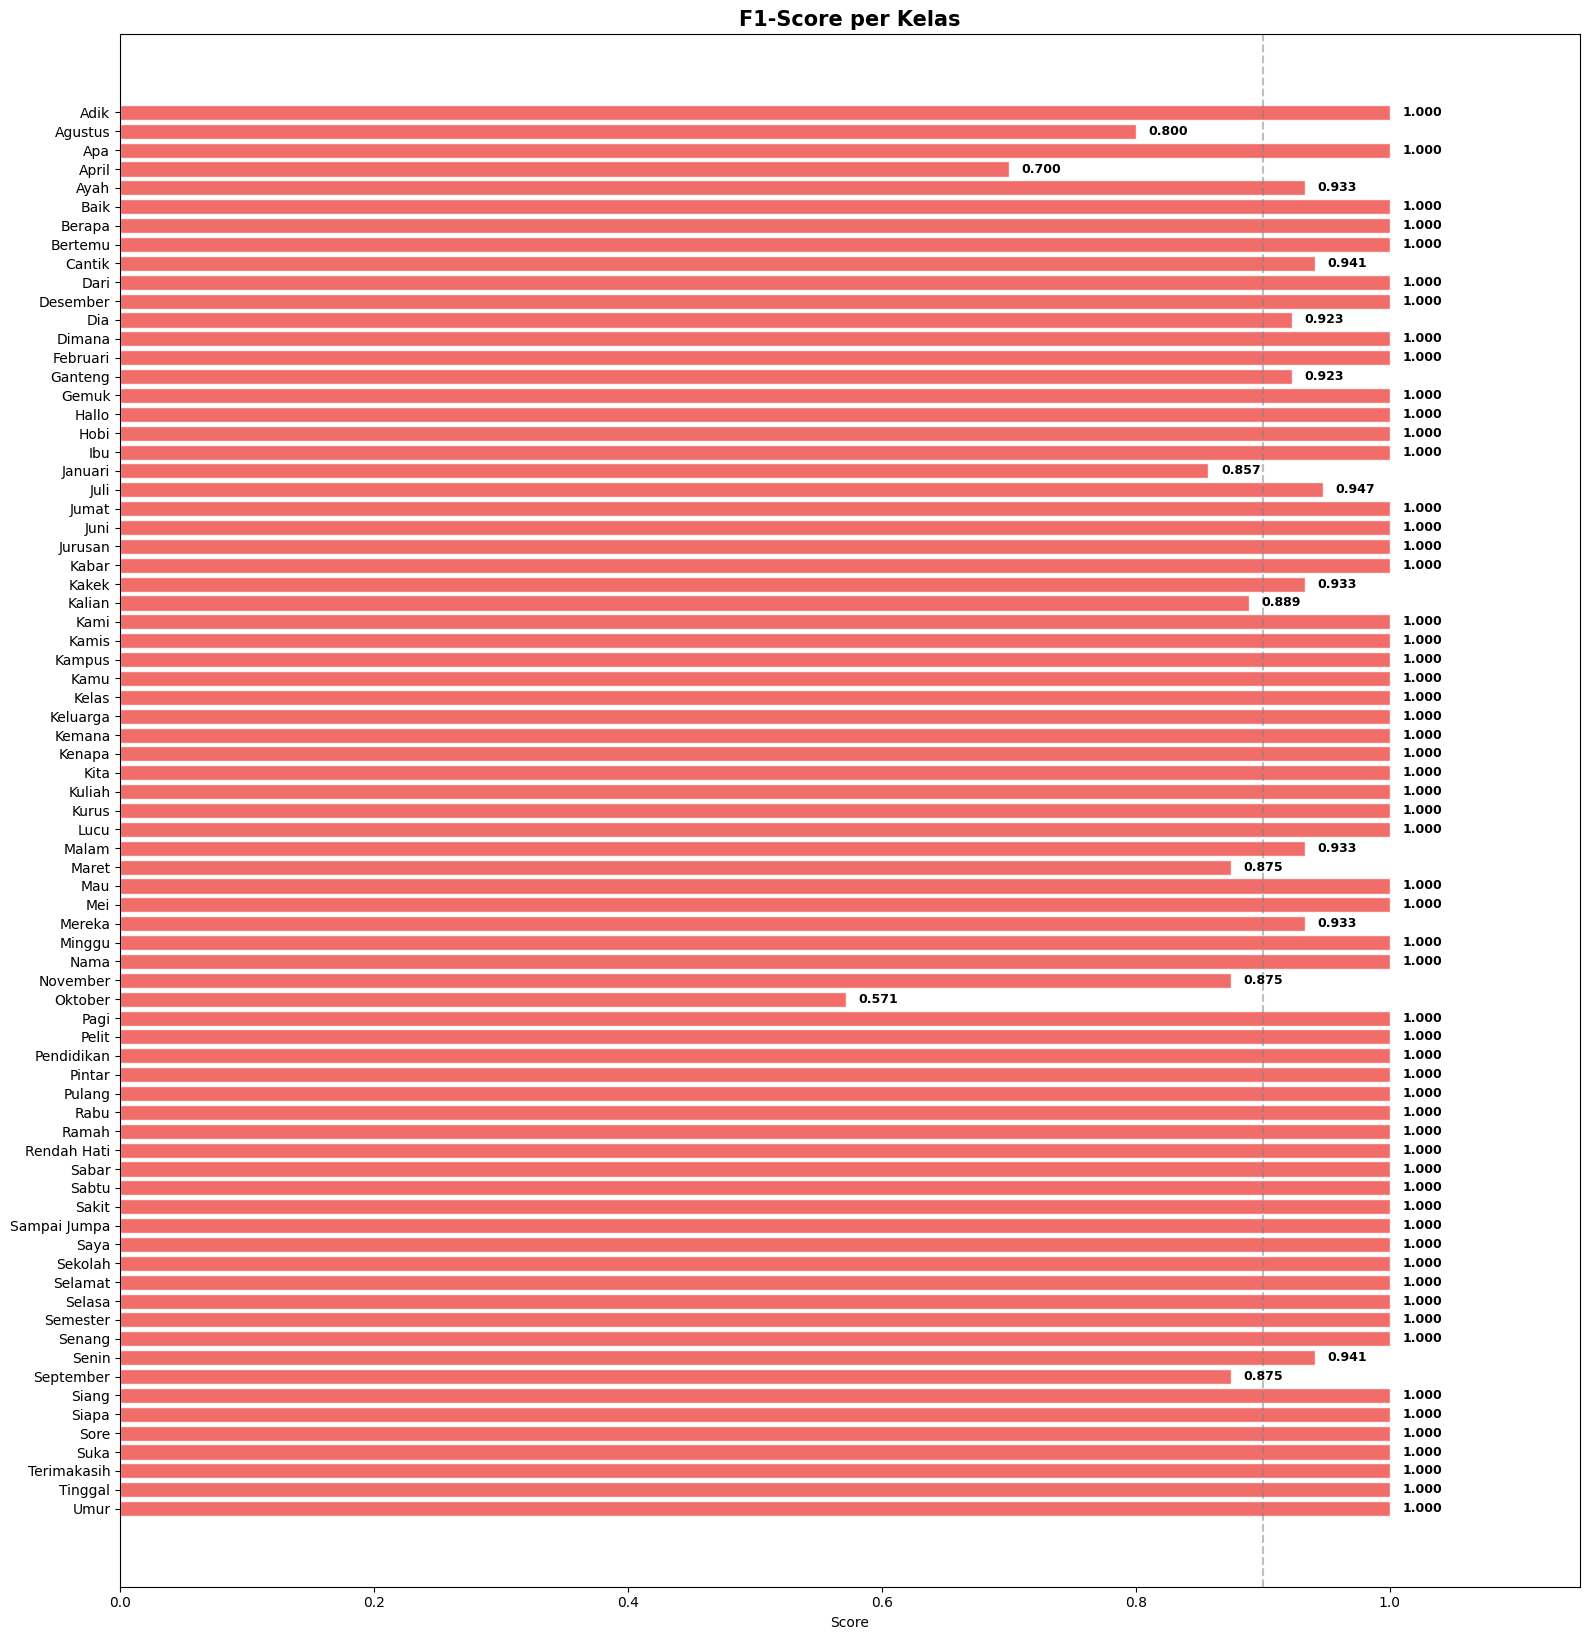

In [23]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

vals = df_report['f1-score'].values
bars = ax.barh(actions, vals, color='#EF5350', alpha=0.85, edgecolor='white')
ax.set_title('F1-Score per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Score')
ax.set_xlim(0, 1.15)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5)
ax.invert_yaxis()

for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_f1score.png', dpi=200, bbox_inches='tight')
plt.show()

In [24]:
print(df_report[['precision','recall','f1-score','support']].to_string())

              precision    recall  f1-score  support
Adik           1.000000  1.000000  1.000000      7.0
Agustus        0.857143  0.750000  0.800000      8.0
Apa            1.000000  1.000000  1.000000      7.0
April          0.583333  0.875000  0.700000      8.0
Ayah           1.000000  0.875000  0.933333      8.0
Baik           1.000000  1.000000  1.000000      8.0
Berapa         1.000000  1.000000  1.000000      7.0
Bertemu        1.000000  1.000000  1.000000      7.0
Cantik         0.888889  1.000000  0.941176      8.0
Dari           1.000000  1.000000  1.000000      7.0
Desember       1.000000  1.000000  1.000000      8.0
Dia            1.000000  0.857143  0.923077      7.0
Dimana         1.000000  1.000000  1.000000      7.0
Februari       1.000000  1.000000  1.000000      8.0
Ganteng        1.000000  0.857143  0.923077      7.0
Gemuk          1.000000  1.000000  1.000000      7.0
Hallo          1.000000  1.000000  1.000000      8.0
Hobi           1.000000  1.000000  1.000000   

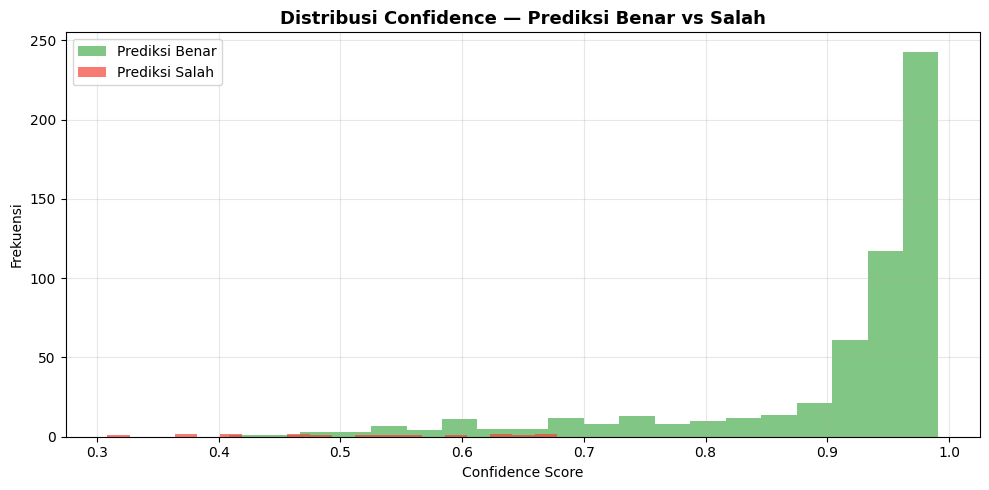

Confidence rata-rata benar : 0.9042
Confidence rata-rata salah : 0.5138


In [25]:
max_conf   = np.max(y_pred_prob, axis=1)
is_correct = (y_pred == y_true)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_conf[is_correct],  bins=20, alpha=0.7,
        color='#4CAF50', label='Prediksi Benar')
ax.hist(max_conf[~is_correct], bins=20, alpha=0.7,
        color='#F44336', label='Prediksi Salah')
ax.set_title('Distribusi Confidence — Prediksi Benar vs Salah', fontweight='bold', fontsize=13)
ax.set_xlabel('Confidence Score'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Confidence rata-rata benar : {max_conf[is_correct].mean():.4f}')
print(f'Confidence rata-rata salah : {max_conf[~is_correct].mean():.4f}')

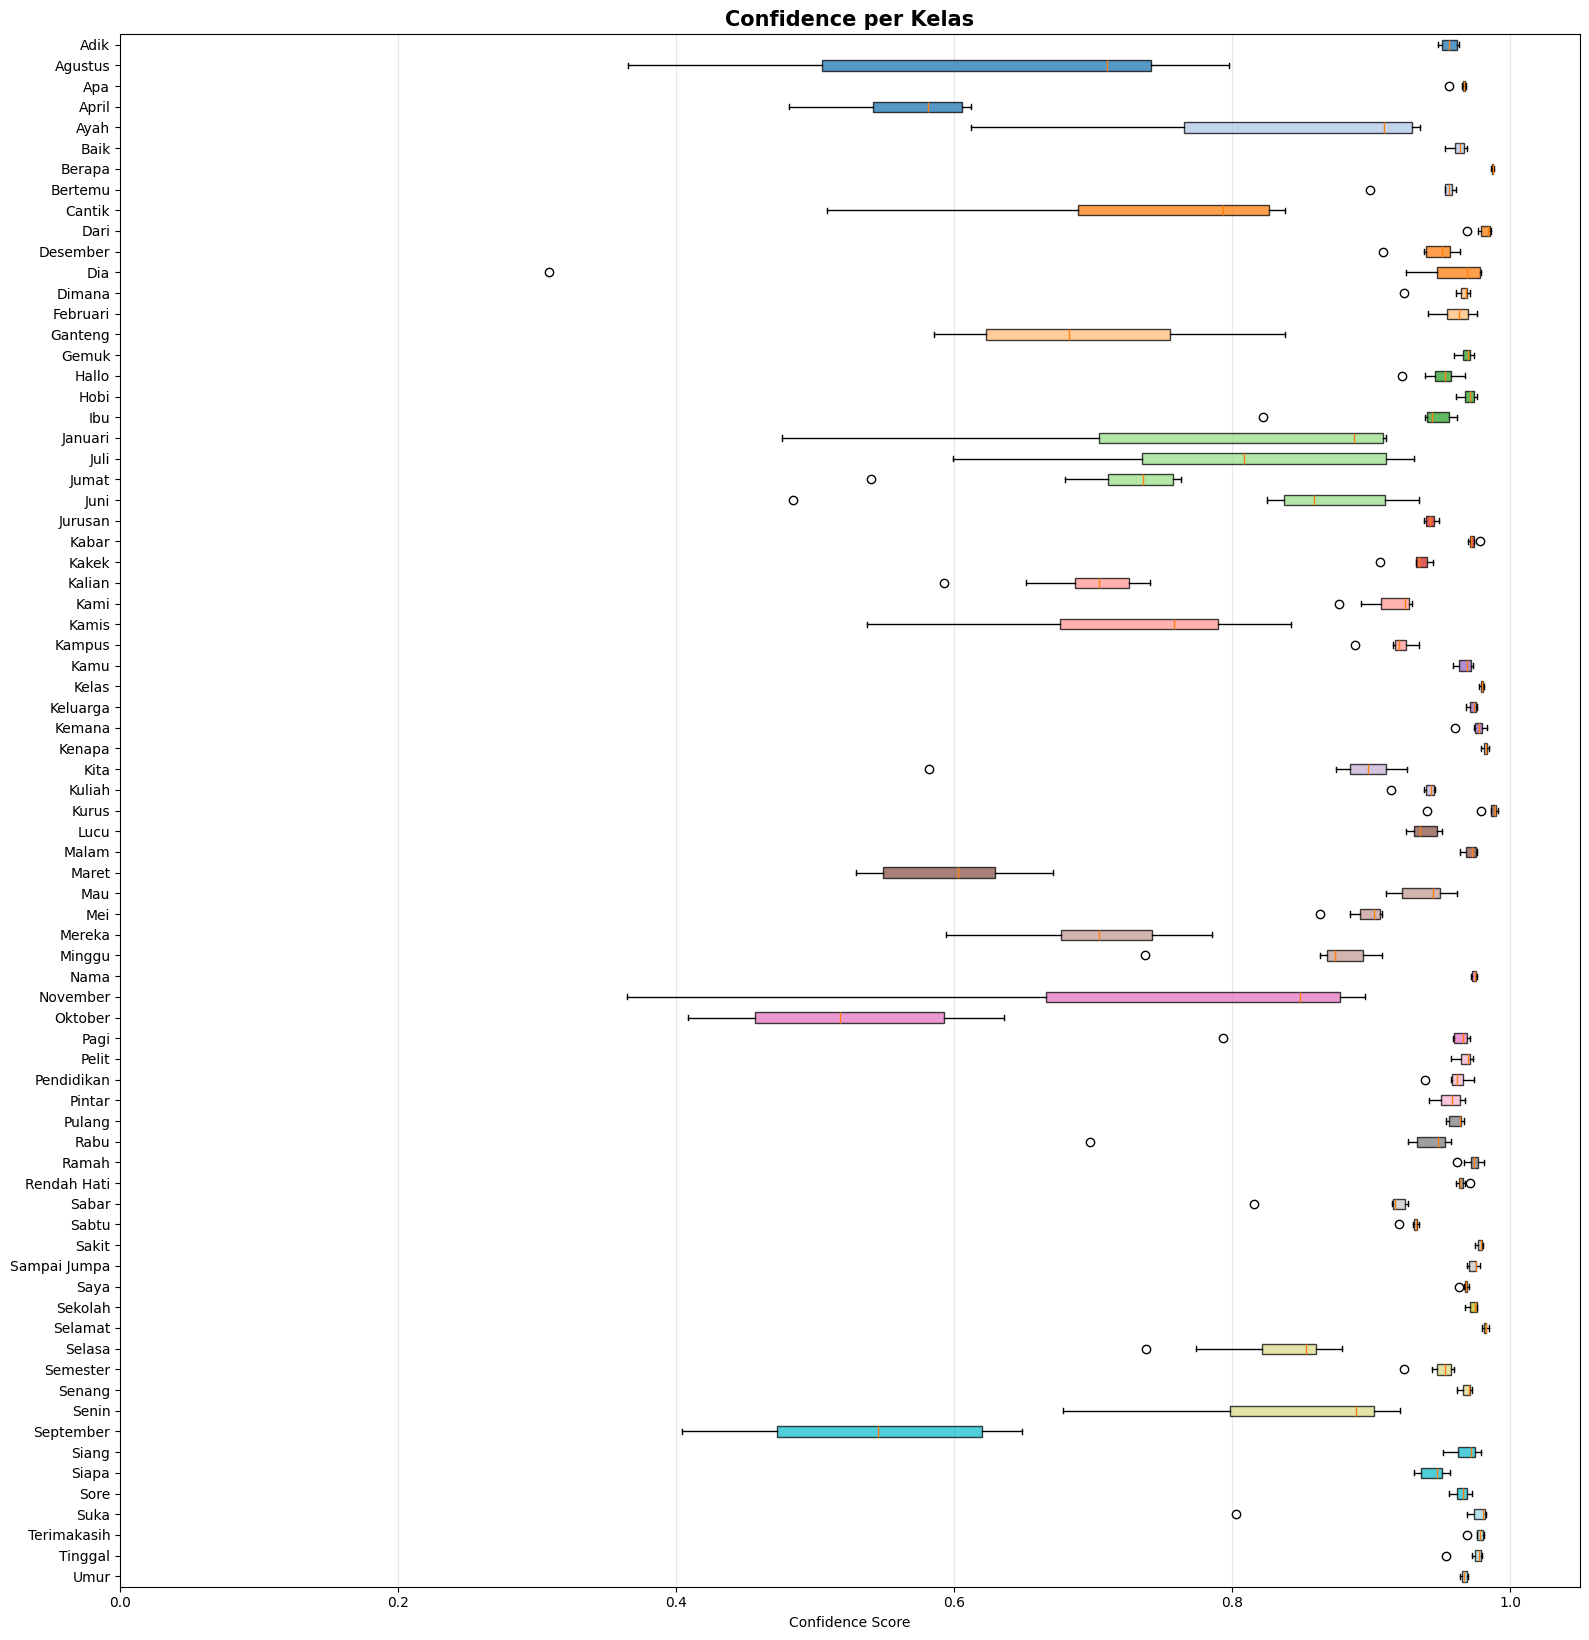

In [26]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(9, n * 0.22)))

bp = ax.boxplot(
    [max_conf[y_true == i] for i in range(n)],
    labels=actions, patch_artist=True,
    vert=False  # boxplot horizontal
)

# generate warna sebanyak jumlah kelas
colors_cycle = plt.cm.tab20(np.linspace(0, 1, n))
for patch, c in zip(bp['boxes'], colors_cycle):
    patch.set_facecolor(c); patch.set_alpha(0.75)

ax.set_title('Confidence per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Confidence Score'); ax.set_xlim(0, 1.05); ax.grid(alpha=0.3, axis='x')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_per_class.png', dpi=200, bbox_inches='tight')
plt.show()

In [27]:
report_full = classification_report(
    y_true, y_pred, target_names=actions, output_dict=True
)

print('=' * 60)
print('        RINGKASAN HASIL TRAINING — SIBI 25 KELAS (v2)')
print('=' * 60)
print(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing')
print(f'  Kelas         : {", ".join(actions)}')
print(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi')
print(f'  Fitur/frame   : {FITUR_PER_FRAME}')
print(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik')
print('-' * 60)
print(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}')
print('-' * 60)
print(f'  Test Accuracy : {acc * 100:.2f}%')
print(f'  Test Loss     : {loss:.4f}')
print(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}')
print(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}')
print('-' * 60)
print('  Per-Class:')
for action in actions:
    r = report_full[action]
    print(f'  {action:12s}  P={r["precision"]:.3f}  '
          f'R={r["recall"]:.3f}  F1={r["f1-score"]:.3f}')
print('=' * 60)
print(f'\n✅ Output model  : {MODEL_OUTPUT}')

with open(f'{PATH_CONFIGURATION_GENERAL}/ringkasan_training.txt', 'w', encoding='utf-8') as f:
    f.write('=' * 60 + '\n')
    f.write('        RINGKASAN HASIL TRAINING — SIBI 25 KELAS (v2)\n')
    f.write('=' * 60 + '\n')
    f.write(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing\n')
    f.write(f'  Kelas         : {", ".join(actions)}\n')
    f.write(f'  Jumlah Kelas  : {len(actions)}\n')
    f.write(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi\n')
    f.write(f'  Fitur/frame   : {FITUR_PER_FRAME}\n')
    f.write(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Test Accuracy : {acc * 100:.2f}%\n')
    f.write(f'  Test Loss     : {loss:.4f}\n')
    f.write(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}\n')
    f.write(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}\n')
    f.write(f'  Macro P       : {report_full["macro avg"]["precision"]:.4f}\n')
    f.write(f'  Macro R       : {report_full["macro avg"]["recall"]:.4f}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Epoch terbaik (val_accuracy) : {np.argmax(history.history["val_accuracy"]) + 1}\n')
    f.write(f'  Epoch terbaik (val_loss)     : {np.argmin(history.history["val_loss"]) + 1}\n')
    f.write(f'  Total epoch berjalan         : {len(history.history["loss"])}\n')
    f.write(f'  Val Accuracy terbaik         : {max(history.history["val_accuracy"]) * 100:.2f}%\n')
    f.write(f'  Val Loss terbaik             : {min(history.history["val_loss"]):.4f}\n')
    f.write('-' * 60 + '\n')
    f.write('  Per-Class Metrics:\n')
    f.write(f'  {"Kelas":<14} {"Precision":>10} {"Recall":>10} {"F1-Score":>10} {"Support":>10}\n')
    f.write('  ' + '-' * 50 + '\n')
    for action in actions:
        r = report_full[action]
        f.write(f'  {action:<14} {r["precision"]:>10.4f} {r["recall"]:>10.4f} '
                f'{r["f1-score"]:>10.4f} {int(r["support"]):>10}\n')
    f.write('-' * 60 + '\n')
    f.write('=' * 60 + '\n')

print('✅ Ringkasan tersimpan : ringkasan_training.txt')

        RINGKASAN HASIL TRAINING — SIBI 25 KELAS (v2)
  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing
  Kelas         : Adik, Agustus, Apa, April, Ayah, Baik, Berapa, Bertemu, Cantik, Dari, Desember, Dia, Dimana, Februari, Ganteng, Gemuk, Hallo, Hobi, Ibu, Januari, Juli, Jumat, Juni, Jurusan, Kabar, Kakek, Kalian, Kami, Kamis, Kampus, Kamu, Kelas, Keluarga, Kemana, Kenapa, Kita, Kuliah, Kurus, Lucu, Malam, Maret, Mau, Mei, Mereka, Minggu, Nama, November, Oktober, Pagi, Pelit, Pendidikan, Pintar, Pulang, Rabu, Ramah, Rendah Hati, Sabar, Sabtu, Sakit, Sampai Jumpa, Saya, Sekolah, Selamat, Selasa, Semester, Senang, Senin, September, Siang, Siapa, Sore, Suka, Terimakasih, Tinggal, Umur
  Total data    : 3834 (asli) → train diaugmentasi
  Fitur/frame   : 258
  Sequence len  : 30 frame @ 30fps = 1.0 detik
------------------------------------------------------------
  Train (aug) / Val / Test : 18781 / 575 / 576
------------------------------------------------------------
